In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [1]:
!nvidia-smi

Sat Oct 31 09:41:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   58C    P8             12W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
import torch

print("PyTorch:", torch.__version__)
print("GPU memory:", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
), "GB")

PyTorch: 2.11.0+cu130
GPU memory: 14.56 GB


In [4]:
import os

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

folders = [
    "models/instantmesh",
    "models/zero123plus",
    "models/rembg",
    "inputs",
    "outputs"
]

for folder in folders:
    os.makedirs(os.path.join(BASE_DIR, folder), exist_ok=True)

print("Drive folders created successfully!")

Drive folders created successfully!


In [5]:
MODEL_DIR = f"{BASE_DIR}/models"

INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"
REMBG_DIR = f"{MODEL_DIR}/rembg"

print("Model directory:", MODEL_DIR)

Model directory: /content/drive/MyDrive/Sketch2Shape_AI/models


In [6]:
from huggingface_hub import hf_hub_download

checkpoint = hf_hub_download(
    repo_id="TencentARC/InstantMesh",
    filename="instant_mesh_large.ckpt",
    local_dir=INSTANTMESH_DIR
)

print("Downloaded:", checkpoint)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


instant_mesh_large.ckpt: reconstructing file:   0%|          |  0.00B / 1.51GB            

instant_mesh_large.ckpt: downloading bytes:           |  0.00B            

Downloaded: /content/drive/MyDrive/Sketch2Shape_AI/models/instantmesh/instant_mesh_large.ckpt


In [7]:
import os

for root, dirs, files in os.walk(INSTANTMESH_DIR):
    for file in files:
        path = os.path.join(root, file)
        print(file, f"({os.path.getsize(path) / (1024**2):.2f} MB)")

instant_mesh_large.ckpt (1444.64 MB)
CACHEDIR.TAG (0.00 MB)
.gitignore (0.00 MB)
instant_mesh_large.ckpt.lock (0.00 MB)
instant_mesh_large.ckpt.metadata (0.00 MB)


In [8]:
from huggingface_hub import hf_hub_download

unet_path = hf_hub_download(
    repo_id="TencentARC/InstantMesh",
    filename="diffusion_pytorch_model.bin",
    local_dir=INSTANTMESH_DIR
)

print(unet_path)

diffusion_pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.73GB            

diffusion_pytorch_model.bin: downloading bytes:           |  0.00B            

/content/drive/MyDrive/Sketch2Shape_AI/models/instantmesh/diffusion_pytorch_model.bin


In [9]:
from huggingface_hub import snapshot_download

zero123_path = snapshot_download(
    repo_id="sudo-ai/zero123plus-v1.2",
    local_dir=ZERO123_DIR
)

print("Zero123++ downloaded:", zero123_path)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 17 files:   0%|          | 0/17 [00:00<?, ?it/s]

Zero123++ downloaded: /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus


In [10]:
import os

for folder in [INSTANTMESH_DIR, ZERO123_DIR]:
    print(f"\n{folder}")

    for root, dirs, files in os.walk(folder):
        for file in files:
            path = os.path.join(root, file)
            if os.path.isfile(path):
                size = os.path.getsize(path) / (1024**2)
                print(f"{file}: {size:.2f} MB")


/content/drive/MyDrive/Sketch2Shape_AI/models/instantmesh
instant_mesh_large.ckpt: 1444.64 MB
diffusion_pytorch_model.bin: 1651.82 MB
CACHEDIR.TAG: 0.00 MB
.gitignore: 0.00 MB
instant_mesh_large.ckpt.lock: 0.00 MB
instant_mesh_large.ckpt.metadata: 0.00 MB
diffusion_pytorch_model.bin.lock: 0.00 MB
diffusion_pytorch_model.bin.metadata: 0.00 MB

/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus
model_index.json: 0.00 MB
.gitattributes: 0.00 MB
CACHEDIR.TAG: 0.00 MB
.gitignore: 0.00 MB
2da07e89919e1a130c9b5add1584c70c7aa065fd.json: 0.00 MB
model_index.json.lock: 0.00 MB
.gitattributes.lock: 0.00 MB
model_index.json.metadata: 0.00 MB
.gitattributes.metadata: 0.00 MB
merges.txt.lock: 0.00 MB
special_tokens_map.json.lock: 0.00 MB
merges.txt.metadata: 0.00 MB
tokenizer_config.json.lock: 0.00 MB
vocab.json.lock: 0.00 MB
special_tokens_map.json.metadata: 0.00 MB
tokenizer_config.json.metadata: 0.00 MB
vocab.json.metadata: 0.00 MB
model.safetensors.lock: 0.00 MB
config.json.lock: 0.00 MB

In [12]:
import torch
from diffusers import DiffusionPipeline, EulerAncestralDiscreteScheduler

print("Diffusers imported successfully!")
print("PyTorch:", torch.__version__)

Diffusers imported successfully!
PyTorch: 2.11.0+cu130


In [14]:
import os
import torch
from diffusers import DiffusionPipeline, EulerAncestralDiscreteScheduler

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

MODEL_DIR = os.path.join(BASE_DIR, "models")
INSTANTMESH_DIR = os.path.join(MODEL_DIR, "instantmesh")
ZERO123_DIR = os.path.join(MODEL_DIR, "zero123plus")

HF_CACHE = os.path.join(MODEL_DIR, "huggingface_cache")

os.makedirs(HF_CACHE, exist_ok=True)

print("All paths configured!")
print("InstantMesh:", INSTANTMESH_DIR)
print("Zero123++:", ZERO123_DIR)
print("Cache:", HF_CACHE)

All paths configured!
InstantMesh: /content/drive/MyDrive/Sketch2Shape_AI/models/instantmesh
Zero123++: /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus
Cache: /content/drive/MyDrive/Sketch2Shape_AI/models/huggingface_cache


In [18]:
%cd /content

!git clone https://github.com/TencentARC/InstantMesh.git

/content
Cloning into 'InstantMesh'...
remote: Enumerating objects: 334, done.
remote: Counting objects: 100% (176/176), done.
remote: Compressing objects: 100% (74/74), done.
remote: Total 334 (delta 130), reused 102 (delta 102), pack-reused 158 (from 1)
Receiving objects: 100% (334/334), 33.55 MiB | 19.18 MiB/s, done.
Resolving deltas: 100% (138/138), done.


In [19]:
import os

REPO_DIR = "/content/InstantMesh"

print("Repository exists:", os.path.exists(REPO_DIR))
print(
    "Custom pipeline exists:",
    os.path.exists(f"{REPO_DIR}/zero123plus/pipeline.py")
)

Repository exists: True
Custom pipeline exists: True


In [20]:
import os
import torch

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"
MODEL_DIR = f"{BASE_DIR}/models"

INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"

REPO_DIR = "/content/InstantMesh"

MODEL_CKPT = f"{INSTANTMESH_DIR}/instant_mesh_large.ckpt"
UNET_CKPT = f"{INSTANTMESH_DIR}/diffusion_pytorch_model.bin"

assert os.path.exists(MODEL_CKPT), "InstantMesh checkpoint missing"
assert os.path.exists(UNET_CKPT), "UNet checkpoint missing"
assert os.path.exists(f"{REPO_DIR}/zero123plus/pipeline.py"), "Custom pipeline missing"

print("All required files verified!")
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

All required files verified!
CUDA: True
GPU: Tesla T4


In [22]:
import torch
from diffusers import DiffusionPipeline, EulerAncestralDiscreteScheduler

%cd /content/InstantMesh

pipeline = DiffusionPipeline.from_pretrained(
    "sudo-ai/zero123plus-v1.2",
    custom_pipeline="zero123plus",
    trust_remote_code=True,
    torch_dtype=torch.float16,
    cache_dir=ZERO123_DIR
)

pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

print("Zero123++ pipeline loaded successfully!")

/content/InstantMesh


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

SafetensorError: Error while deserializing header: header too large

In [23]:
import os
import struct

for root, dirs, files in os.walk(ZERO123_DIR):
    for file in files:
        if file.endswith(".safetensors"):
            path = os.path.join(root, file)

            with open(path, "rb") as f:
                first_bytes = f.read(8)

            header_size = struct.unpack("<Q", first_bytes)[0]

            file_size = os.path.getsize(path)

            print(f"\nFile: {file}")
            print(f"Size: {file_size / (1024**3):.2f} GB")
            print(f"Header size: {header_size:,} bytes")
            print(f"Header valid: {8 <= header_size < file_size}")


File: model.safetensors
Size: 0.63 GB
Header size: 44,704 bytes
Header valid: True

File: diffusion_pytorch_model.safetensors
Size: 3.23 GB
Header size: 83,600 bytes
Header valid: True

File: diffusion_pytorch_model.safetensors
Size: 0.16 GB
Header size: 27,608 bytes
Header valid: True

File: model.safetensors
Size: 1.18 GB
Header size: 63,632 bytes
Header valid: True

File: model.safetensors
Size: 0.00 GB
Header size: 7,809,856,579,203,706,414 bytes
Header valid: False

File: diffusion_pytorch_model.safetensors
Size: 0.00 GB
Header size: 7,809,856,579,203,706,414 bytes
Header valid: False

File: diffusion_pytorch_model.safetensors
Size: 0.00 GB
Header size: 7,809,856,579,203,706,414 bytes
Header valid: False

File: model.safetensors
Size: 0.00 GB
Header size: 7,809,856,579,203,706,414 bytes
Header valid: False


In [24]:
import os

for root, dirs, files in os.walk(ZERO123_DIR):
    for file in files:
        if file.endswith(".safetensors"):
            path = os.path.join(root, file)
            size = os.path.getsize(path)

            if size < 1024:
                print("CORRUPTED:", path, size, "bytes")

CORRUPTED: /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/text_encoder/model.safetensors 79 bytes
CORRUPTED: /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/unet/diffusion_pytorch_model.safetensors 79 bytes
CORRUPTED: /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/vae/diffusion_pytorch_model.safetensors 79 bytes
CORRUPTED: /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/vision_encoder/model.safetensors 79 bytes


In [25]:
import os

deleted = []

for root, dirs, files in os.walk(ZERO123_DIR):
    for file in files:
        if file.endswith(".safetensors"):
            path = os.path.join(root, file)

            if os.path.getsize(path) < 1024:
                os.remove(path)
                deleted.append(path)

print("Deleted corrupted files:")
for path in deleted:
    print(path)

Deleted corrupted files:
/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/text_encoder/model.safetensors
/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/unet/diffusion_pytorch_model.safetensors
/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/vae/diffusion_pytorch_model.safetensors
/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/vision_encoder/model.safetensors


In [26]:
from huggingface_hub import hf_hub_download
import os

repo_id = "sudo-ai/zero123plus-v1.2"

files_to_download = [
    "text_encoder/model.safetensors",
    "unet/diffusion_pytorch_model.safetensors",
    "vae/diffusion_pytorch_model.safetensors",
    "vision_encoder/model.safetensors"
]

for filename in files_to_download:
    print(f"\nDownloading: {filename}")

    path = hf_hub_download(
        repo_id=repo_id,
        filename=filename,
        cache_dir=ZERO123_DIR,
        force_download=True
    )

    print("Downloaded:", path)

print("\nAll four files downloaded!")


Downloading: text_encoder/model.safetensors


text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  681MB            

text_encoder/model.safetensors: downloading bytes:           |  0.00B            

Downloaded: /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/text_encoder/model.safetensors

Downloading: unet/diffusion_pytorch_model.safetensors


unet/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.46GB            

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

... (3 outputs left out)

Downloaded: /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/vae/diffusion_pytorch_model.safetensors

Downloading: vision_encoder/model.safetensors


vision_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

vision_encoder/model.safetensors: downloading bytes:           |  0.00B            

Downloaded: /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/vision_encoder/model.safetensors

All four files downloaded!


In [27]:
import os
import struct

invalid_files = []

for root, dirs, files in os.walk(ZERO123_DIR):
    for file in files:
        if file.endswith(".safetensors"):
            path = os.path.join(root, file)
            size = os.path.getsize(path)

            with open(path, "rb") as f:
                header_size = struct.unpack("<Q", f.read(8))[0]

            valid = 8 <= header_size < size

            if not valid:
                invalid_files.append(path)

            print(
                f"{'VALID' if valid else 'INVALID'} | "
                f"{file} | {size / (1024**3):.2f} GB"
            )

print("\nInvalid files:", len(invalid_files))

VALID | model.safetensors | 0.63 GB
VALID | diffusion_pytorch_model.safetensors | 3.23 GB
VALID | diffusion_pytorch_model.safetensors | 0.16 GB
VALID | model.safetensors | 1.18 GB
INVALID | model.safetensors | 0.00 GB
INVALID | diffusion_pytorch_model.safetensors | 0.00 GB
INVALID | diffusion_pytorch_model.safetensors | 0.00 GB
INVALID | model.safetensors | 0.00 GB

Invalid files: 4


In [28]:
import os

for root, dirs, files in os.walk(ZERO123_DIR):
    for file in files:
        if file.endswith(".safetensors") and os.path.getsize(
            os.path.join(root, file)
        ) < 1024:
            print(os.path.join(root, file))

/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/text_encoder/model.safetensors
/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/unet/diffusion_pytorch_model.safetensors
/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/vae/diffusion_pytorch_model.safetensors
/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/vision_encoder/model.safetensors


In [29]:
from huggingface_hub import hf_hub_download

for filename in [
    "text_encoder/model.safetensors",
    "unet/diffusion_pytorch_model.safetensors",
    "vae/diffusion_pytorch_model.safetensors",
    "vision_encoder/model.safetensors"
]:
    path = hf_hub_download(
        repo_id="sudo-ai/zero123plus-v1.2",
        filename=filename,
        cache_dir=ZERO123_DIR
    )

    print(filename, "->", path)
    print("Size:", os.path.getsize(path))

text_encoder/model.safetensors -> /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/text_encoder/model.safetensors
Size: 79
unet/diffusion_pytorch_model.safetensors -> /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/unet/diffusion_pytorch_model.safetensors
Size: 79
vae/diffusion_pytorch_model.safetensors -> /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/vae/diffusion_pytorch_model.safetensors
Size: 79
vision_encoder/model.safetensors -> /content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/models--sudo-ai--zero123plus-v1.2/snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd/vision_encoder/model.safetensors
Size: 79


In [30]:
import os
from huggingface_hub import hf_hub_download

RECOVERY_DIR = "/content/zero123plus_recovery"
os.makedirs(RECOVERY_DIR, exist_ok=True)

files_to_download = [
    "text_encoder/model.safetensors",
    "unet/diffusion_pytorch_model.safetensors",
    "vae/diffusion_pytorch_model.safetensors",
    "vision_encoder/model.safetensors"
]

for filename in files_to_download:
    path = hf_hub_download(
        repo_id="sudo-ai/zero123plus-v1.2",
        filename=filename,
        local_dir=RECOVERY_DIR,
        force_download=True
    )

    size_mb = os.path.getsize(path) / (1024 ** 2)
    print(f"{filename}: {size_mb:.2f} MB")
    

text_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B /  681MB            

text_encoder/model.safetensors: downloading bytes:           |  0.00B            

text_encoder/model.safetensors: 649.28 MB


unet/diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 3.46GB            

unet/diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

unet/diffusion_pytorch_model.safetensors: 3303.27 MB


... (2 outputs left out)

vae/diffusion_pytorch_model.safetensors: 159.58 MB


vision_encoder/model.safetensors: reconstructing file:   0%|          |  0.00B / 1.26GB            

vision_encoder/model.safetensors: downloading bytes:           |  0.00B            

vision_encoder/model.safetensors: 1205.65 MB


In [31]:
import os
import shutil

RECOVERY_DIR = "/content/zero123plus_recovery"

SNAPSHOT_DIR = (
    ZERO123_DIR
    + "/models--sudo-ai--zero123plus-v1.2/snapshots/"
    + "2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

files = [
    "text_encoder/model.safetensors",
    "unet/diffusion_pytorch_model.safetensors",
    "vae/diffusion_pytorch_model.safetensors",
    "vision_encoder/model.safetensors"
]

# Verify all downloaded files before replacing anything
for filename in files:
    source = os.path.join(RECOVERY_DIR, filename)
    size_mb = os.path.getsize(source) / (1024 ** 2)
    print(f"{filename}: {size_mb:.2f} MB")

    if size_mb < 1:
        raise ValueError(f"Invalid or incomplete download: {filename}")

# Replace corrupted files
for filename in files:
    source = os.path.join(RECOVERY_DIR, filename)
    destination = os.path.join(SNAPSHOT_DIR, filename)

    os.makedirs(os.path.dirname(destination), exist_ok=True)
    shutil.copy2(source, destination)

print("\nAll four model files replaced successfully.")

text_encoder/model.safetensors: 649.28 MB
unet/diffusion_pytorch_model.safetensors: 3303.27 MB
vae/diffusion_pytorch_model.safetensors: 159.58 MB
vision_encoder/model.safetensors: 1205.65 MB

All four model files replaced successfully.


In [32]:
import os
from safetensors import safe_open

files = [
    "text_encoder/model.safetensors",
    "unet/diffusion_pytorch_model.safetensors",
    "vae/diffusion_pytorch_model.safetensors",
    "vision_encoder/model.safetensors"
]

for filename in files:
    path = os.path.join(SNAPSHOT_DIR, filename)

    try:
        with safe_open(path, framework="pt", device="cpu") as f:
            keys = list(f.keys())

        print(f"VALID: {filename} | Tensors: {len(keys)}")

    except Exception as e:
        print(f"INVALID: {filename} | {e}")

VALID: text_encoder/model.safetensors | Tensors: 372
VALID: unet/diffusion_pytorch_model.safetensors | Tensors: 686
VALID: vae/diffusion_pytorch_model.safetensors | Tensors: 248
VALID: vision_encoder/model.safetensors | Tensors: 520


In [33]:
import os
import torch
from diffusers import DiffusionPipeline

print("Model directory exists:", os.path.isdir(SNAPSHOT_DIR))
print("Custom pipeline exists:",
      os.path.isfile("/content/InstantMesh/zero123plus/pipeline.py"))

pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline="/content/InstantMesh/zero123plus",
    torch_dtype=torch.float16,
    trust_remote_code=True,
    local_files_only=True
)

print("Zero123++ loaded successfully!")

Model directory exists: True
Custom pipeline exists: True


Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Zero123++ loaded successfully!


In [34]:
import torch

print("GPU:", torch.cuda.get_device_name(0))
print("Free GPU memory:",
      round(torch.cuda.mem_get_info()[0] / 1024**3, 2), "GB")

pipeline.enable_model_cpu_offload()

print("CPU offloading enabled successfully!")

GPU: Tesla T4
Free GPU memory: 14.46 GB
CPU offloading enabled successfully!


In [36]:
import os

EXAMPLES_DIR = "/content/InstantMesh/examples"

images = [
    f for f in os.listdir(EXAMPLES_DIR)
    if f.lower().endswith((".png", ".jpg", ".jpeg", ".webp"))
]

print("Available images:", images[:10])

Available images: ['chair_watermelon.png', 'pikachu.png', 'teasure_chest.jpg', 'bird.jpg', 'house2.jpg', 'plant.jpg', 'hatsune_miku.png', 'sea_turtle.png', 'cartoon_dinosaur.png', 'fruit.jpg']


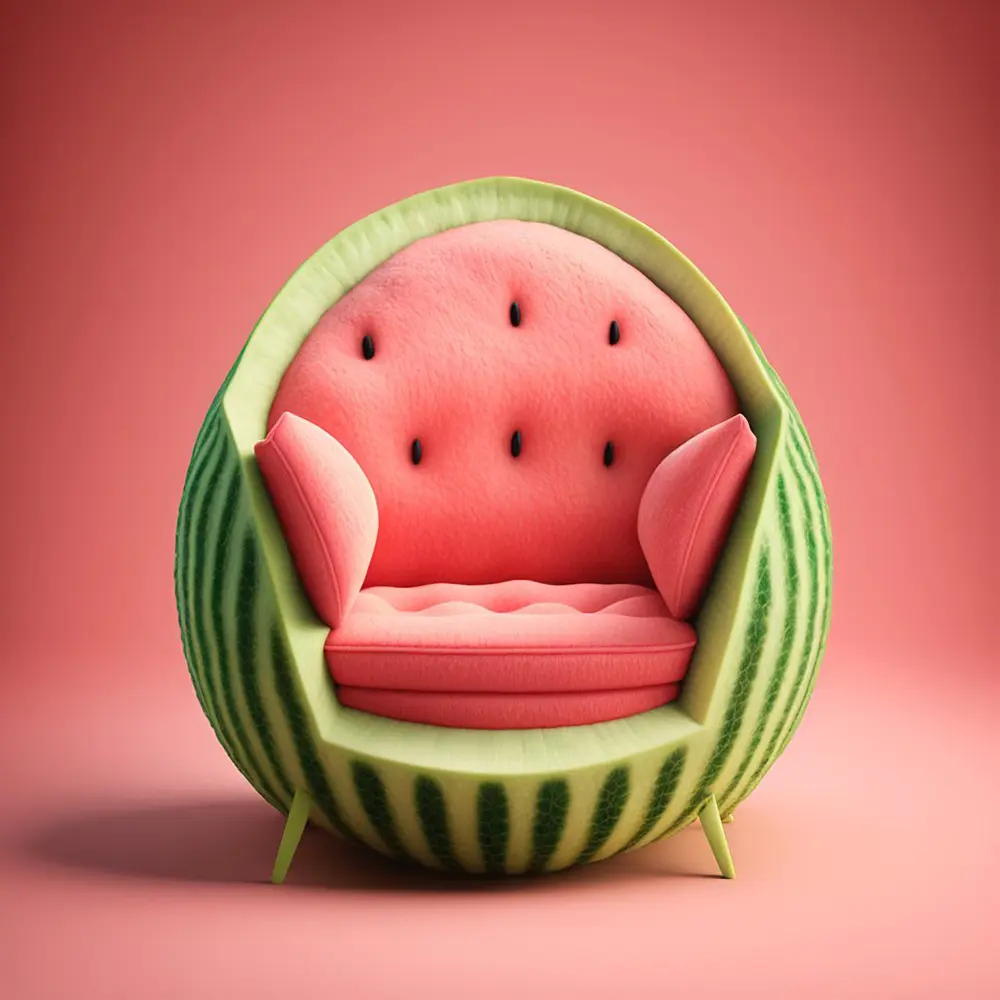

In [37]:
from PIL import Image
from IPython.display import display

sample_path = os.path.join(EXAMPLES_DIR, images[0])

input_image = Image.open(sample_path).convert("RGB")
display(input_image)

In [39]:
import torch
from diffusers import DiffusionPipeline

# Release the previous pipeline
del pipeline
torch.cuda.empty_cache()

# Load directly onto GPU
pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline="/content/InstantMesh/zero123plus",
    torch_dtype=torch.float16,
    trust_remote_code=True,
    local_files_only=True
)

pipeline = pipeline.to("cuda")

print("Pipeline device:", pipeline.device)
print("GPU:", torch.cuda.get_device_name(0))
print("Allocated VRAM:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/520 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Pipeline device: cuda:0
GPU: Tesla T4
Allocated VRAM: 3.76 GB


  0%|          | 0/75 [00:00<?, ?it/s]

Generated views: 1


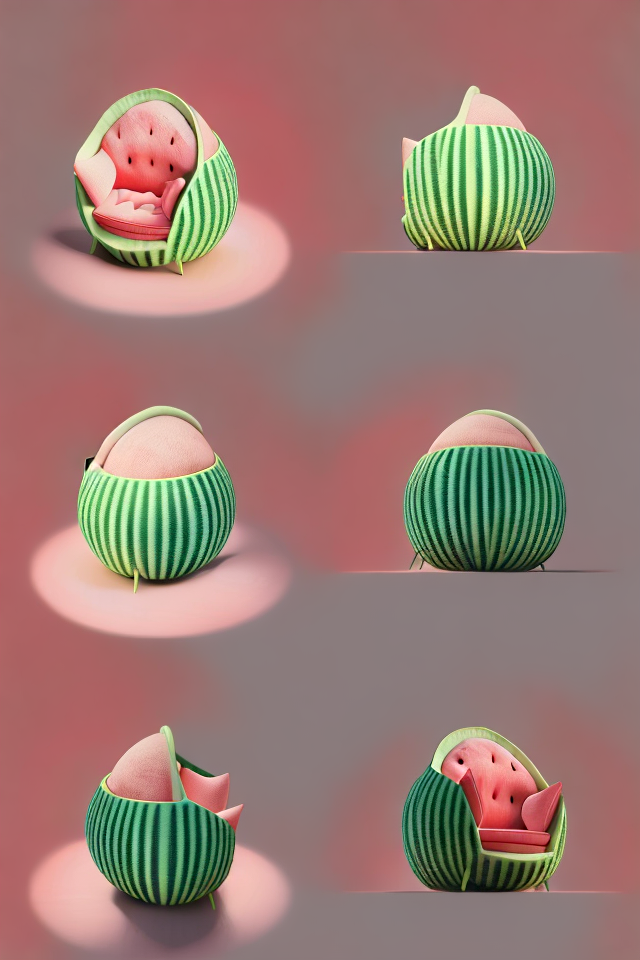

In [40]:
with torch.inference_mode():
    result = pipeline(
        input_image,
        num_inference_steps=75
    )

generated_images = result.images

print("Generated views:", len(generated_images))

for img in generated_images:
    display(img)

In [41]:
print("Generated views:", len(generated_images))
print("View dimensions:", generated_images[0].size)
print("Pipeline device:", pipeline.device)

print("InstantMesh checkpoint exists:", os.path.exists(MODEL_CKPT))
print("InstantMesh UNet exists:", os.path.exists(UNET_CKPT))

Generated views: 1
View dimensions: (640, 960)
Pipeline device: cuda:0
InstantMesh checkpoint exists: True
InstantMesh UNet exists: True


In [42]:
import numpy as np
import torch
from einops import rearrange

# Extract the contact sheet
multi_view_image = generated_images[0]

# Convert to tensor
images = np.asarray(multi_view_image, dtype=np.float32) / 255.0
images = torch.from_numpy(images).permute(2, 0, 1).contiguous().float()

# Split into six individual camera views
images = rearrange(
    images,
    'c (n h) (m w) -> (n m) c h w',
    n=3,
    m=2
)

print("Six-view tensor shape:", images.shape)

Six-view tensor shape: torch.Size([6, 3, 320, 320])


In [43]:
del pipeline
torch.cuda.empty_cache()

print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

GPU memory allocated: 0.17 GB


In [44]:
import os

CONFIG_PATH = "/content/InstantMesh/configs/instant-mesh-large.yaml"

print("Config exists:", os.path.exists(CONFIG_PATH))
print("Checkpoint exists:", os.path.exists(MODEL_CKPT))

Config exists: True
Checkpoint exists: True


In [ ]:
import os
import shutil

RECOVERY_DIR = "/content/zero123plus_recovery"

SNAPSHOT_DIR = (
    ZERO123_DIR
    + "/models--sudo-ai--zero123plus-v1.2/snapshots/"
    + "2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

files = [
    "text_encoder/model.safetensors",
    "unet/diffusion_pytorch_model.safetensors",
    "vae/diffusion_pytorch_model.safetensors",
    "vision_encoder/model.safetensors"
]

# Verify all downloaded files before replacing anything
for filename in files:
    source = os.path.join(RECOVERY_DIR, filename)
    size_mb = os.path.getsize(source) / (1024 ** 2)
    print(f"{filename}: {size_mb:.2f} MB")

    if size_mb < 1:
        raise ValueError(f"Invalid or incomplete download: {filename}")

# Replace corrupted files
for filename in files:
    source = os.path.join(RECOVERY_DIR, filename)
    destination = os.path.join(SNAPSHOT_DIR, filename)

    os.makedirs(os.path.dirname(destination), exist_ok=True)
    shutil.copy2(source, destination)

print("\nAll four model files replaced successfully.")

text_encoder/model.safetensors: 649.28 MB
unet/diffusion_pytorch_model.safetensors: 3303.27 MB
vae/diffusion_pytorch_model.safetensors: 159.58 MB
vision_encoder/model.safetensors: 1205.65 MB

All four model files replaced successfully.


In [45]:
import os
import numpy as np
import torch
from einops import rearrange

# Split the Zero123++ contact sheet into six views
sheet = np.asarray(generated_images[0], dtype=np.float32) / 255.0

images = torch.from_numpy(sheet).permute(2, 0, 1).contiguous().float()

images = rearrange(
    images,
    'c (n h) (m w) -> (n m) c h w',
    n=3,
    m=2
)

print("Six-view tensor:", images.shape)

# Check InstantMesh files
CONFIG_PATH = "/content/InstantMesh/configs/instant-mesh-large.yaml"

print("Config exists:", os.path.exists(CONFIG_PATH))
print("Checkpoint exists:", os.path.exists(MODEL_CKPT))
print("UNet exists:", os.path.exists(UNET_CKPT))

Six-view tensor: torch.Size([6, 3, 320, 320])
Config exists: True
Checkpoint exists: True
UNet exists: True


In [46]:
import os
import numpy as np
import torch
from einops import rearrange

# Split the Zero123++ contact sheet into six views
sheet = np.asarray(generated_images[0], dtype=np.float32) / 255.0

images = torch.from_numpy(sheet).permute(2, 0, 1).contiguous().float()

images = rearrange(
    images,
    'c (n h) (m w) -> (n m) c h w',
    n=3,
    m=2
)

print("Six-view tensor:", images.shape)

# Check InstantMesh files
CONFIG_PATH = "/content/InstantMesh/configs/instant-mesh-large.yaml"

print("Config exists:", os.path.exists(CONFIG_PATH))
print("Checkpoint exists:", os.path.exists(MODEL_CKPT))
print("UNet exists:", os.path.exists(UNET_CKPT))

Six-view tensor: torch.Size([6, 3, 320, 320])
Config exists: True
Checkpoint exists: True
UNet exists: True


In [49]:
!nvcc --version

nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0


In [50]:
import torch
from torch.utils.cpp_extension import CUDA_HOME

print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("CUDA_HOME:", CUDA_HOME)
print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
PyTorch CUDA: 13.0
CUDA_HOME: /usr/local/cuda
GPU: Tesla T4


In [51]:
!pip install git+https://github.com/NVlabs/nvdiffrast.git --no-build-isolation -v

Using pip 26.2.2 from /usr/local/lib/python3.13/dist-packages/pip (python 3.13)
  Cloning https://github.com/NVlabs/nvdiffrast.git to /tmp/pip-req-build-giufwig5
  Running command git version
  git version 2.43.0
  Running command git clone --filter=blob:none https://github.com/NVlabs/nvdiffrast.git /tmp/pip-req-build-giufwig5
  Cloning into '/tmp/pip-req-build-giufwig5'...
  Updating files:   2% (2/85)
  Updating files:   3% (3/85)
  Updating files:   4% (4/85)
  Updating files:   5% (5/85)
  Updating files:   7% (6/85)
  Updating files:   8% (7/85)
  Updating files:   9% (8/85)
  Updating files:  10% (9/85)
  Updating files:  11% (10/85)
  Updating files:  12% (11/85)
  Updating files:  14% (12/85)
  Updating files:  15% (13/85)
  Updating files:  16% (14/85)
  Updating files:  17% (15/85)
  Updating files:  18% (16/85)
  Updating files:  20% (17/85)
  Updating files:  21% (18/85)
  Updating files:  22% (19/85)
  Updating files:  23% (20/85)
  Updating files:  24% (21/85)
  Updating 

In [52]:
import nvdiffrast.torch as dr

print("nvdiffrast imported successfully!")
print("Rasterizer available:", hasattr(dr, "RasterizeGLContext"))

nvdiffrast imported successfully!
Rasterizer available: True


In [55]:
import transformers
print("Transformers version:", transformers.__version__)

Transformers version: 5.21.0


In [56]:
%pip install transformers==4.34.1

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.7/7.7 MB 82.9 MB/s  0:00:00
  Created wheel for tokenizers: filename=tokenizers-0.14.1-cp313-cp313-linux_x86_64.whl size=2690840 sha256=8d27a68f88a6b41bc10660a925ed1062409b6db413030012376204299e79888f
  Stored in directory: /root/.cache/pip/wheels/94/25/bb/c9f33ac8f2e2aee88fac4d39eb0189247f9131e0001702a04c
Successfully built tokenizers
  Attempting uninstall: huggingface-hub
    Found existing installation: huggingface_hub 1.33.0
    Uninstalling huggingface_hub-1.33.0:
      Successfully uninstalled huggingface_hub-1.33.00/3 [huggingface-hub]
  Attempting uninstall: tokenizers━━━━━━━━━━━━━━ 0/3 [huggingface-hub]
    Found existing installation: tokenizers 0.23.30/3 [huggingface-hub]
    Uninstalling tokenizers-0.23.3:━━━━━━━━━ 0/3 [huggingface-hub]
      Successful

In [58]:
import torch
import transformers.pytorch_utils as pytorch_utils

def find_pruneable_heads_and_indices(
    heads, n_heads, head_size, already_pruned_heads
):
    mask = torch.ones(n_heads, head_size)

    heads = set(heads) - already_pruned_heads

    for head in heads:
        head -= sum(1 for h in already_pruned_heads if h < head)
        mask[head] = 0

    index = torch.arange(mask.numel())[mask.view(-1).bool()]

    return heads, index.long()


pytorch_utils.find_pruneable_heads_and_indices = (
    find_pruneable_heads_and_indices
)

print("InstantMesh compatibility shim installed!")

InstantMesh compatibility shim installed!


In [59]:
from transformers.pytorch_utils import (
    find_pruneable_heads_and_indices,
    prune_linear_layer
)

print("Both DINO helper imports successful!")

Both DINO helper imports successful!


In [60]:
import transformers
import torch

from transformers.pytorch_utils import (
    find_pruneable_heads_and_indices,
    prune_linear_layer
)

print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("DINO compatibility: OK")

Transformers: 5.21.0
PyTorch: 2.11.0+cu130
CUDA available: True
DINO compatibility: OK


In [62]:
%pip install xatlas

In [63]:
import xatlas
print("xatlas installed successfully!")

xatlas installed successfully!


In [67]:
%pip install trimesh

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 751.5/751.5 kB 21.4 MB/s  0:00:00


In [68]:
import trimesh
print("trimesh version:", trimesh.__version__)

trimesh version: 5.2.0


In [69]:
model = instantiate_from_config(model_config)

config.json:   0%|          | 0.00/454 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  343MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: facebook/dino-vitb16
Key                                              | Status  | 
-------------------------------------------------+---------+-
encoder.layer.{0...11}.adaLN_modulation.1.bias   | MISSING | 
encoder.layer.{0...11}.adaLN_modulation.1.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


preprocessor_config.json:   0%|          | 0.00/244 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

In [70]:
print("Loading InstantMesh checkpoint...")

checkpoint = torch.load(
    MODEL_CKPT,
    map_location="cpu",
    weights_only=False
)

state_dict = {
    k[14:]: v
    for k, v in checkpoint["state_dict"].items()
    if k.startswith("lrm_generator.")
    and "source_camera" not in k
}

result = model.load_state_dict(state_dict, strict=True)

print("Checkpoint loaded successfully!")
print("Missing keys:", result.missing_keys)
print("Unexpected keys:", result.unexpected_keys)

del checkpoint, state_dict

Loading InstantMesh checkpoint...
Checkpoint loaded successfully!
Missing keys: []
Unexpected keys: []


In [71]:
device = torch.device("cuda")

print("Moving InstantMesh to GPU...")
model = model.to(device)

print("Initializing FlexiCubes geometry...")
model.init_flexicubes_geometry(device, fovy=30.0)

model = model.eval()

print("\nInstantMesh is ready!")
print("GPU:", torch.cuda.get_device_name(0))
print(
    "Allocated VRAM:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Moving InstantMesh to GPU...
Initializing FlexiCubes geometry...

InstantMesh is ready!
GPU: Tesla T4
Allocated VRAM: 1.67 GB


In [72]:
from src.utils.camera_util import get_zero123plus_input_cameras
from torchvision.transforms import v2

# Add batch dimension and move to GPU
input_images = images.unsqueeze(0).to(device)

# Resize to the expected input resolution
input_images = v2.functional.resize(
    input_images,
    (320, 320),
    interpolation=3,
    antialias=True
).clamp(0, 1)

# Generate camera parameters for the six views
input_cameras = get_zero123plus_input_cameras(
    batch_size=1,
    radius=4.0
).to(device)

print("Input images:", input_images.shape)
print("Input cameras:", input_cameras.shape)

Input images: torch.Size([1, 6, 3, 320, 320])
Input cameras: torch.Size([1, 6, 16])


In [74]:
from src.models.encoder.dino import ViTModel

def compatible_get_head_mask(self, head_mask, num_hidden_layers):
    if head_mask is None:
        return [None] * num_hidden_layers

    return self._convert_head_mask_to_5d(
        head_mask, num_hidden_layers
    )

ViTModel.get_head_mask = compatible_get_head_mask

print("DINO get_head_mask compatibility patch applied!")

DINO get_head_mask compatibility patch applied!


In [75]:
print("Generating 3D planes...")

with torch.no_grad():
    planes = model.forward_planes(
        input_images,
        input_cameras
    )

print("3D planes generated successfully!")
print("Planes shape:", planes.shape)
print(
    "GPU memory:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Generating 3D planes...
3D planes generated successfully!
Planes shape: torch.Size([1, 3, 80, 64, 64])
GPU memory: 1.68 GB


In [76]:
import inspect

print("extract_mesh signature:")
print(inspect.signature(model.extract_mesh))

print("\nMethod source:")
print(inspect.getsource(model.extract_mesh))

extract_mesh signature:
(planes: torch.Tensor, use_texture_map: bool = False, texture_resolution: int = 1024, **kwargs)

Method source:
    def extract_mesh(
        self, 
        planes: torch.Tensor, 
        use_texture_map: bool = False,
        texture_resolution: int = 1024,
        **kwargs,
    ):
        '''
        Extract a 3D mesh from FlexiCubes. Only support batch_size 1.
        :param planes: triplane features
        :param use_texture_map: use texture map or vertex color
        :param texture_resolution: the resolution of texure map
        '''
        assert planes.shape[0] == 1
        device = planes.device

        # predict geometry first
        mesh_v, mesh_f, sdf, deformation, v_deformed, sdf_reg_loss = self.get_geometry_prediction(planes)
        vertices, faces = mesh_v[0], mesh_f[0]

        if not use_texture_map:
            # query vertex colors
            vertices_tensor = vertices.unsqueeze(0)
            vertices_colors = self.synthesizer.get_textu

In [77]:
import trimesh
import numpy as np

print("trimesh:", trimesh.__version__)
print("NumPy:", np.__version__)
print("Mesh export dependencies ready!")

trimesh: 5.2.0
NumPy: 2.1.3
Mesh export dependencies ready!


In [79]:
import inspect
import torch

print("Current grid resolution:", model.grid_res)
print("Geometry vertices:", model.geometry.verts.shape)
print("Geometry indices:", model.geometry.indices.shape)

print(
    "Initialization signature:",
    inspect.signature(model.init_flexicubes_geometry)
)

print("Allocated VRAM:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
print("Free VRAM:",
      round(torch.cuda.mem_get_info()[0] / 1024**3, 2), "GB")

Current grid resolution: 128
Geometry vertices: torch.Size([2146689, 3])
Geometry indices: torch.Size([2097152, 8])
Initialization signature: (device, fovy=50.0)
Allocated VRAM: 3.64 GB
Free VRAM: 10.65 GB


In [80]:
import inspect

print(inspect.getsource(model.init_flexicubes_geometry))

print("\nModel configuration:")
print(OmegaConf.to_yaml(model_config))

    def init_flexicubes_geometry(self, device, fovy=50.0):
        camera = PerspectiveCamera(fovy=fovy, device=device)
        renderer = NeuralRender(device, camera_model=camera)
        self.geometry = FlexiCubesGeometry(
            grid_res=self.grid_res, 
            scale=self.grid_scale, 
            renderer=renderer, 
            render_type='neural_render',
            device=device,
        )


Model configuration:
target: src.models.lrm_mesh.InstantMesh
params:
  encoder_feat_dim: 768
  encoder_freeze: false
  encoder_model_name: facebook/dino-vitb16
  transformer_dim: 1024
  transformer_layers: 16
  transformer_heads: 16
  triplane_low_res: 32
  triplane_high_res: 64
  triplane_dim: 80
  rendering_samples_per_ray: 128
  grid_res: 128
  grid_scale: 2.1



In [81]:
import torch
import trimesh
import nvdiffrast.torch as dr

print("All mesh dependencies available!")

All mesh dependencies available!


In [82]:
# Clear previous geometry and cached GPU memory
del model.geometry
torch.cuda.empty_cache()

# Reduce grid resolution
model.grid_res = 64

# Reinitialize geometry
model.init_flexicubes_geometry(device, fovy=30.0)

print("New grid resolution:", model.grid_res)
print("Geometry vertices:", model.geometry.verts.shape)
print("Geometry indices:", model.geometry.indices.shape)

print(
    "Allocated VRAM:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

New grid resolution: 64
Geometry vertices: torch.Size([274625, 3])
Geometry indices: torch.Size([262144, 8])
Allocated VRAM: 3.57 GB


In [83]:
print("Extracting mesh at resolution 64...")

torch.cuda.empty_cache()

with torch.inference_mode():
    vertices, faces, vertex_colors = model.extract_mesh(
        planes,
        use_texture_map=False
    )

print("Mesh extraction successful!")
print("Vertices:", vertices.shape)
print("Faces:", faces.shape)
print("Colors:", vertex_colors.shape)

Extracting mesh at resolution 64...
Mesh extraction successful!
Vertices: (47498, 3)
Faces: (94940, 3)
Colors: (47498, 3)


In [84]:
import trimesh
import numpy as np

print("trimesh:", trimesh.__version__)
print("NumPy:", np.__version__)

trimesh: 5.2.0
NumPy: 2.1.3


In [85]:
import os

OUTPUT_DIR = f"{BASE_DIR}/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    vertex_colors=vertex_colors,
    process=False
)

OBJ_PATH = f"{OUTPUT_DIR}/sketch2shape_output.obj"
GLB_PATH = f"{OUTPUT_DIR}/sketch2shape_output.glb"

mesh.export(OBJ_PATH)
mesh.export(GLB_PATH)

print("OBJ saved:", OBJ_PATH)
print("GLB saved:", GLB_PATH)
print("Watertight:", mesh.is_watertight)
print("Bounds:", mesh.bounds)
print("Volume:", mesh.volume)

OBJ saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/sketch2shape_output.obj
GLB saved: /content/drive/MyDrive/Sketch2Shape_AI/outputs/sketch2shape_output.glb
Watertight: True
Bounds: [[-0.98442602 -0.9876219  -0.98727494]
 [ 0.98546702  0.98166424  0.98822898]]
Volume: 4.378310445092648


In [86]:
import trimesh
import matplotlib
import matplotlib.pyplot as plt

print("Visualization dependencies ready!")

Visualization dependencies ready!


In [87]:
mesh.show()

In [89]:
print("Camera tensor shape:", input_cameras.shape)
print("\nCamera parameters:")
print(input_cameras)

Camera tensor shape: torch.Size([1, 6, 16])

Camera parameters:
tensor([[[-5.0000e-01, -2.9620e-01,  8.1380e-01,  3.2552e+00,  8.6603e-01,
          -1.7101e-01,  4.6985e-01,  1.8794e+00,  0.0000e+00,  9.3969e-01,
           3.4202e-01,  1.3681e+00,  1.8660e+00,  1.8660e+00,  5.0000e-01,
           5.0000e-01],
         [-1.0000e+00,  1.0633e-17,  6.0302e-17,  2.4121e-16,  6.1232e-17,
           1.7365e-01,  9.8481e-01,  3.9392e+00,  0.0000e+00,  9.8481e-01,
          -1.7365e-01, -6.9459e-01,  1.8660e+00,  1.8660e+00,  5.0000e-01,
           5.0000e-01],
         [-5.0000e-01,  2.9620e-01, -8.1380e-01, -3.2552e+00, -8.6603e-01,
          -1.7101e-01,  4.6985e-01,  1.8794e+00,  0.0000e+00,  9.3969e-01,
           3.4202e-01,  1.3681e+00,  1.8660e+00,  1.8660e+00,  5.0000e-01,
           5.0000e-01],
         [ 5.0000e-01, -1.5038e-01, -8.5287e-01, -3.4115e+00, -8.6603e-01,
          -8.6824e-02, -4.9240e-01, -1.9696e+00,  0.0000e+00,  9.8481e-01,
          -1.7365e-01, -6.9459e-01,  1.

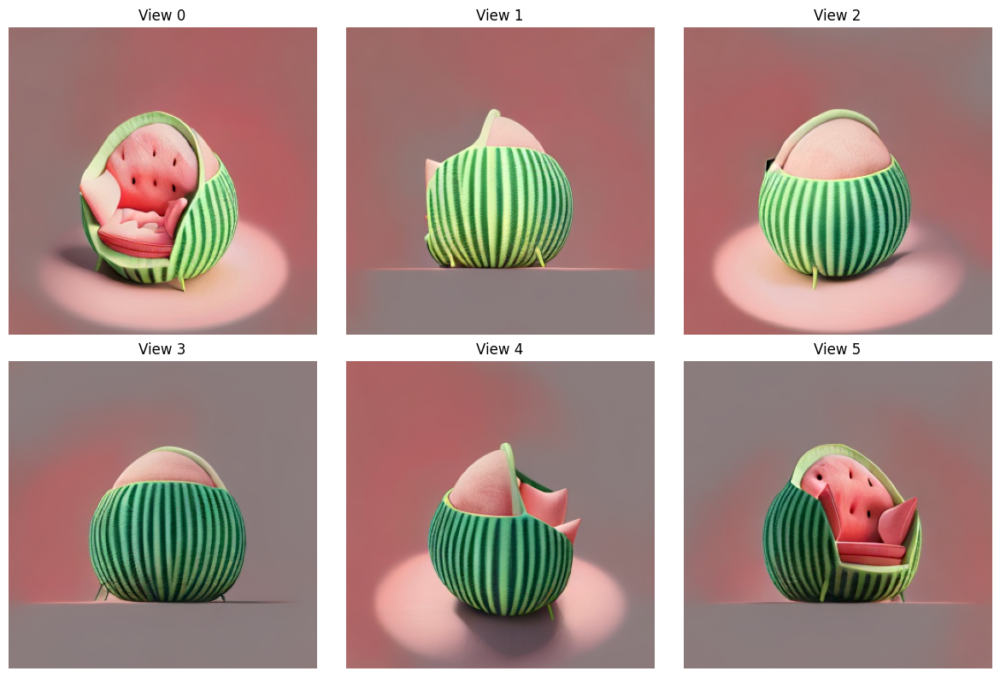

In [90]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for i, ax in enumerate(axes.flat):
    img = input_images[0, i].detach().cpu().permute(1, 2, 0).numpy()

    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(f"View {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [91]:
import inspect

print(inspect.getsource(get_zero123plus_input_cameras))

def get_zero123plus_input_cameras(batch_size=1, radius=4.0, fov=30.0):
    """
    Get the input camera parameters.
    """
    azimuths = np.array([30, 90, 150, 210, 270, 330]).astype(float)
    elevations = np.array([20, -10, 20, -10, 20, -10]).astype(float)
    
    c2ws = spherical_camera_pose(azimuths, elevations, radius)
    c2ws = c2ws.float().flatten(-2)

    Ks = FOV_to_intrinsics(fov).unsqueeze(0).repeat(6, 1, 1).float().flatten(-2)

    extrinsics = c2ws[:, :12]
    intrinsics = torch.stack([Ks[:, 0], Ks[:, 4], Ks[:, 2], Ks[:, 5]], dim=-1)
    cameras = torch.cat([extrinsics, intrinsics], dim=-1)

    return cameras.unsqueeze(0).repeat(batch_size, 1, 1)



In [92]:
import inspect

from src.models.encoder.dino_wrapper import DinoWrapper

print("===== DINO WRAPPER FORWARD =====")
print(inspect.getsource(DinoWrapper.forward))

print("\n===== INSTANTMESH INFERENCE FILES =====")

import glob

files = glob.glob(
    REPO_DIR + "/**/infer.py",
    recursive=True
)

for file in files:
    print(file)

===== DINO WRAPPER FORWARD =====
    def forward(self, image, camera):
        # image: [B, N, C, H, W]
        # camera: [B, N, D]
        # RGB image with [0,1] scale and properly sized
        if image.ndim == 5:
            image = rearrange(image, 'b n c h w -> (b n) c h w')
        dtype = image.dtype
        inputs = self.processor(
            images=image.float(), 
            return_tensors="pt", 
            do_rescale=False, 
            do_resize=False,
        ).to(self.model.device).to(dtype)
        # embed camera
        N = camera.shape[1]
        camera_embeddings = self.camera_embedder(camera)
        camera_embeddings = rearrange(camera_embeddings, 'b n d -> (b n) d')
        embeddings = camera_embeddings
        # This resampling of positional embedding uses bicubic interpolation
        outputs = self.model(**inputs, adaln_input=embeddings, interpolate_pos_encoding=True)
        last_hidden_states = outputs.last_hidden_state
        return last_hidden_states


=

In [93]:
INFER_PATH = files[0]

with open(INFER_PATH, "r") as f:
    source = f.read()

for keyword in ["preprocess", "load_image", "normalize", "images"]:
    print(f"\n===== {keyword} =====")
    for i, line in enumerate(source.splitlines()):
        if keyword.lower() in line.lower():
            print(f"{i+1}: {line}")

IndexError: list index out of range

In [94]:
import os

print("Repository:", REPO_DIR)

for root, dirs, filenames in os.walk(REPO_DIR):
    dirs[:] = [
        d for d in dirs
        if d not in [".git", "__pycache__", "venv"]
    ]

    for filename in filenames:
        if filename.endswith(".py") and any(
            word in filename.lower()
            for word in ["infer", "run", "demo"]
        ):
            print(os.path.join(root, filename))

Repository: /content/InstantMesh
/content/InstantMesh/run.py
/content/InstantMesh/src/utils/infer_util.py


In [95]:
print("Root files:")
print(os.listdir(REPO_DIR))

Root files:
['README.md', '.gitignore', 'assets', 'train.py', 'configs', 'src', 'LICENSE', 'examples', 'zero123plus', '.git', 'app.py', 'requirements.txt', 'run.py', 'docker']


In [96]:
import os

# Read main inference script
run_path = os.path.join(REPO_DIR, "run.py")

with open(run_path, "r") as f:
    run_source = f.read()

print("=" * 60)
print("INSTANTMESH run.py")
print("=" * 60)
print(run_source)

INSTANTMESH run.py
import os
import argparse
import numpy as np
import torch
import rembg
from PIL import Image
from torchvision.transforms import v2
from pytorch_lightning import seed_everything
from omegaconf import OmegaConf
from einops import rearrange, repeat
from tqdm import tqdm
from huggingface_hub import hf_hub_download
from diffusers import DiffusionPipeline, EulerAncestralDiscreteScheduler

from src.utils.train_util import instantiate_from_config
from src.utils.camera_util import (
    FOV_to_intrinsics, 
    get_zero123plus_input_cameras,
    get_circular_camera_poses,
)
from src.utils.mesh_util import save_obj, save_obj_with_mtl
from src.utils.infer_util import remove_background, resize_foreground, save_video


def get_render_cameras(batch_size=1, M=120, radius=4.0, elevation=20.0, is_flexicubes=False):
    """
    Get the rendering camera parameters.
    """
    c2ws = get_circular_camera_poses(M=M, radius=radius, elevation=elevation)
    if is_flexicubes:
        cameras

In [98]:
%pip install rembg

INFO: pip is looking at multiple versions of numba to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 81.4 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 42.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.7/13.7 MB 42.2 MB/s  0:00:006m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 72.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.7/59.7 MB 65.3 MB/s  0:00:006m0:00:0100:01
  Attempting uninstall: pillow
    Found existing installation: pillow 11.3.0
    Uninstalling pillow-11.3.0:
      Successfully uninstalled pillow-11.3.0━━━━ 0/7 [pillow]
  Attempting uninstall: numpy━━━━━━━━━━━━━━━━━━━ 0/7 [pillow]
    Found existing installation: numpy 2.1.3 0/7 [pillow]
    Uninstalling numpy-2.1.3:━━━━━━━━━━━━━━━ 0/7 [pillow]
      Successfully uninstalled numpy-2.1.3━━━━━━━━━━━━━━━━━━━━━━━━ 1/7 [numpy]
  Attempting uninstal

In [100]:
%pip install onnxruntime

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 73.0 MB/s  0:00:006m0:00:01


In [101]:
import onnxruntime as ort
import rembg

print("ONNX Runtime:", ort.__version__)
print("Available providers:", ort.get_available_providers())
print("rembg imported successfully!")

ONNX Runtime: 1.31.1
Available providers: ['AzureExecutionProvider', 'CPUExecutionProvider']
rembg imported successfully!


In [102]:
import inspect
from src.utils.infer_util import remove_background, resize_foreground

print("===== REMOVE BACKGROUND =====")
print(inspect.getsource(remove_background))

print("\n===== RESIZE FOREGROUND =====")
print(inspect.getsource(resize_foreground))

===== REMOVE BACKGROUND =====
def remove_background(image: PIL.Image.Image,
    rembg_session: Any = None,
    force: bool = False,
    **rembg_kwargs,
) -> PIL.Image.Image:
    do_remove = True
    if image.mode == "RGBA" and image.getextrema()[3][0] < 255:
        do_remove = False
    do_remove = do_remove or force
    if do_remove:
        image = rembg.remove(image, session=rembg_session, **rembg_kwargs)
    return image


===== RESIZE FOREGROUND =====
def resize_foreground(
    image: PIL.Image.Image,
    ratio: float,
) -> PIL.Image.Image:
    image = np.array(image)
    assert image.shape[-1] == 4
    alpha = np.where(image[..., 3] > 0)
    y1, y2, x1, x2 = (
        alpha[0].min(),
        alpha[0].max(),
        alpha[1].min(),
        alpha[1].max(),
    )
    # crop the foreground
    fg = image[y1:y2, x1:x2]
    # pad to square
    size = max(fg.shape[0], fg.shape[1])
    ph0, pw0 = (size - fg.shape[0]) // 2, (size - fg.shape[1]) // 2
    ph1, pw1 = size - fg.shape[0] - ph

In [103]:
import rembg
import onnxruntime as ort
import PIL
import numpy as np

print("rembg: OK")
print("ONNX Runtime:", ort.__version__)
print("Pillow:", PIL.__version__)
print("NumPy:", np.__version__)

rembg: OK
ONNX Runtime: 1.31.1
Pillow: 11.3.0
NumPy: 2.1.3


Original image: (1000, 1000)


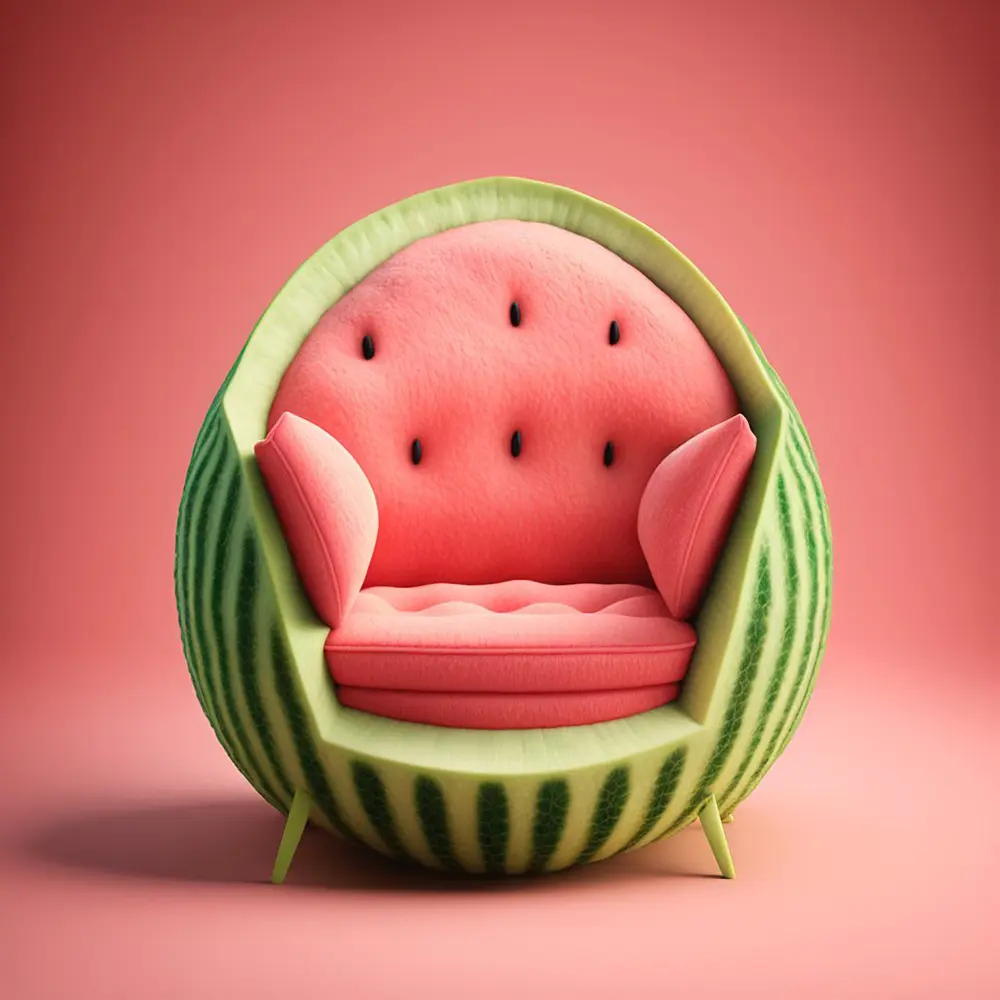

In [104]:
from PIL import Image
from src.utils.infer_util import remove_background, resize_foreground
import rembg

INPUT_IMAGE_PATH = "/content/InstantMesh/examples/chair_watermelon.png"

original_image = Image.open(INPUT_IMAGE_PATH).convert("RGB")

print("Original image:", original_image.size)
display(original_image)

In [105]:
# Initialize background-removal session
rembg_session = rembg.new_session()

# Remove background
processed_image = remove_background(
    original_image,
    rembg_session
)

# Resize foreground to 85%
processed_image = resize_foreground(
    processed_image,
    ratio=0.85
)

print("Processed image:", processed_image.size)
print("Image mode:", processed_image.mode)

display(processed_image)

  0%|                                              | 0.00/1.02G [00:00<?, ?B/s]

: 

: 

: 

In [1]:
import rembg
import onnxruntime as ort

print("rembg:", rembg.__version__)
print("ONNX Runtime:", ort.__version__)

# Explicitly select a smaller model
rembg_session = rembg.new_session("u2net")

print("Background removal model loaded successfully!")

rembg: 2.0.86
ONNX Runtime: 1.31.1


  0%|                                               | 0.00/176M [00:00<?, ?B/s]

Background removal model loaded successfully!


In [2]:
import rembg

rembg_session = rembg.new_session("u2net")

print("U2Net model loaded successfully!")

U2Net model loaded successfully!


In [4]:
import os
import sys

REPO_DIR = "/content/InstantMesh"

os.chdir(REPO_DIR)

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

print("Current directory:", os.getcwd())
print("Repository exists:", os.path.exists(REPO_DIR))
print("src folder exists:", os.path.exists(f"{REPO_DIR}/src"))

Current directory: /content/InstantMesh
Repository exists: True
src folder exists: True


In [5]:
from src.utils.infer_util import remove_background, resize_foreground

print("Preprocessing functions imported successfully!")

Preprocessing functions imported successfully!


Original: (1000, 1000)
Processed: (851, 851)
Mode: RGBA


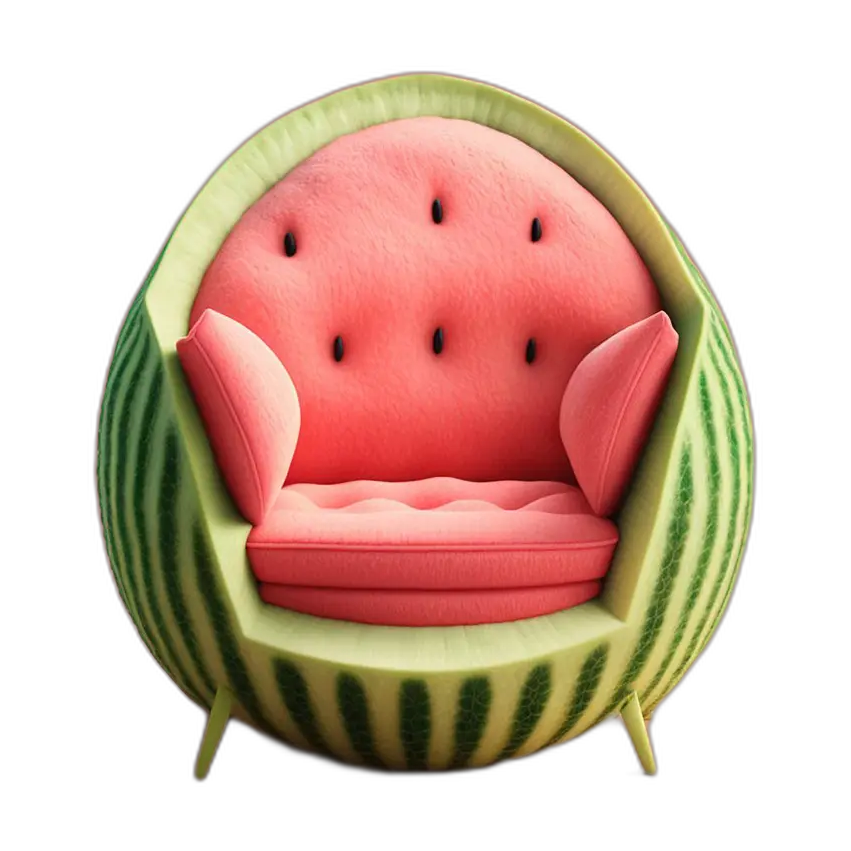

In [6]:
from PIL import Image

INPUT_IMAGE_PATH = "/content/InstantMesh/examples/chair_watermelon.png"

original_image = Image.open(INPUT_IMAGE_PATH).convert("RGB")

processed_image = remove_background(
    original_image,
    rembg_session
)

processed_image = resize_foreground(processed_image, 0.85)

print("Original:", original_image.size)
print("Processed:", processed_image.size)
print("Mode:", processed_image.mode)

display(processed_image)

Original: (1000, 1000)
Processed: (851, 851)
Mode: RGBA


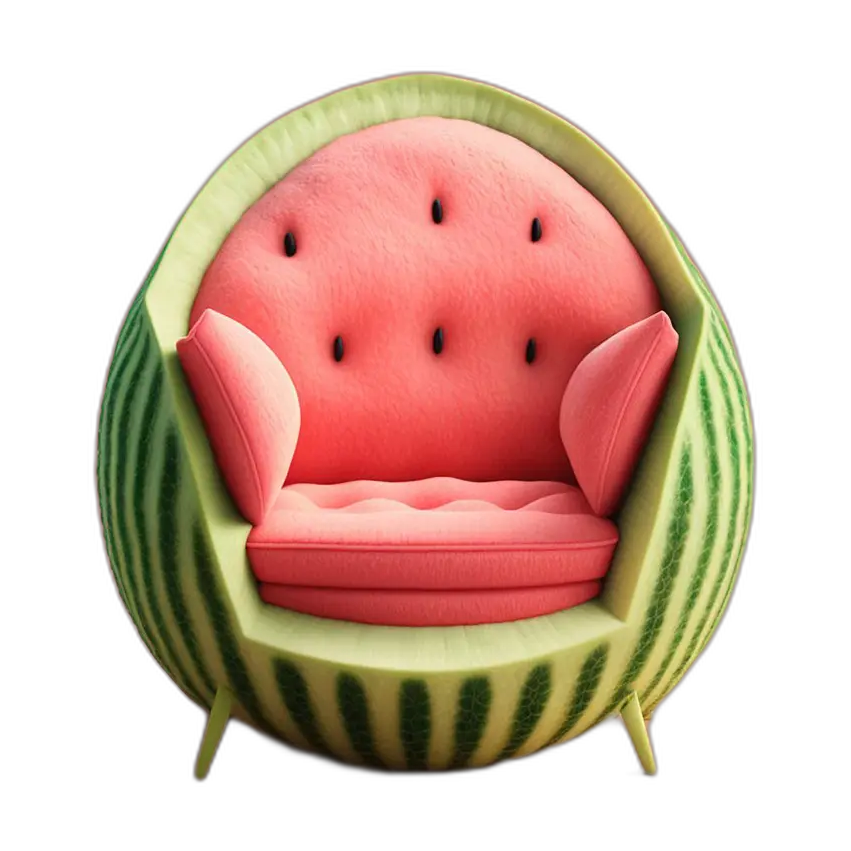

In [7]:
from PIL import Image

INPUT_IMAGE_PATH = "/content/InstantMesh/examples/chair_watermelon.png"

original_image = Image.open(INPUT_IMAGE_PATH).convert("RGB")

processed_image = remove_background(
    original_image,
    rembg_session
)

processed_image = resize_foreground(processed_image, 0.85)

print("Original:", original_image.size)
print("Processed:", processed_image.size)
print("Mode:", processed_image.mode)

display(processed_image)

In [8]:
rembg_session = rembg.new_session("u2net")

In [9]:
import numpy as np

print("Image mode:", processed_image.mode)
print("Image size:", processed_image.size)

alpha = np.array(processed_image.getchannel("A"))

print("Transparent pixels:", np.sum(alpha == 0))
print("Opaque pixels:", np.sum(alpha == 255))
print("Alpha range:", alpha.min(), alpha.max())

Image mode: RGBA
Image size: (851, 851)
Transparent pixels: 345638
Opaque pixels: 83465
Alpha range: 0 255


In [11]:
import os

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

MODEL_DIR = f"{BASE_DIR}/models"
INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"
HF_CACHE = f"{MODEL_DIR}/huggingface_cache"

os.makedirs(f"{BASE_DIR}/examples", exist_ok=True)
os.makedirs(f"{BASE_DIR}/outputs", exist_ok=True)

print("Base directory exists:", os.path.exists(BASE_DIR))

Base directory exists: True


In [12]:
PROCESSED_PATH = f"{BASE_DIR}/examples/processed_chair.png"

processed_image.save(PROCESSED_PATH)

print("Saved successfully:", PROCESSED_PATH)

Saved successfully: /content/drive/MyDrive/Sketch2Shape_AI/examples/processed_chair.png


In [13]:
PROCESSED_PATH = f"{BASE_DIR}/examples/processed_chair.png"

os.makedirs(os.path.dirname(PROCESSED_PATH), exist_ok=True)
processed_image.save(PROCESSED_PATH)

print("Saved:", PROCESSED_PATH)

Saved: /content/drive/MyDrive/Sketch2Shape_AI/examples/processed_chair.png


In [14]:
import os

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"
MODEL_DIR = f"{BASE_DIR}/models"
INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"

MODEL_CKPT = f"{INSTANTMESH_DIR}/instant_mesh_large.ckpt"
UNET_CKPT = f"{INSTANTMESH_DIR}/diffusion_pytorch_model.bin"

print("InstantMesh checkpoint:", os.path.exists(MODEL_CKPT))
print("Custom UNet checkpoint:", os.path.exists(UNET_CKPT))

if os.path.exists(UNET_CKPT):
    print("UNet size:", round(os.path.getsize(UNET_CKPT) / 1024**3, 2), "GB")

InstantMesh checkpoint: True
Custom UNet checkpoint: True
UNet size: 1.61 GB


In [17]:
import huggingface_hub
import importlib.metadata as metadata

print("Hugging Face Hub:", huggingface_hub.__version__)
print("Installed package:", metadata.version("huggingface-hub"))

try:
    from huggingface_hub.constants import HF_HOME
    print("HF_HOME:", HF_HOME)
except ImportError as e:
    print("HF_HOME ERROR:", e)

print("\nDiffusers package version:", metadata.version("diffusers"))
print("Transformers version:", metadata.version("transformers"))

Hugging Face Hub: 0.17.3
Installed package: 0.17.3
HF_HOME ERROR: cannot import name 'HF_HOME' from 'huggingface_hub.constants' (/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py)

Diffusers package version: 0.42.1
Transformers version: 4.34.1


In [18]:
%pip install --upgrade "huggingface_hub>=1.32.0,<3.0"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 857.0/857.0 kB 31.6 MB/s  0:00:00
  Attempting uninstall: huggingface_hub
    Found existing installation: huggingface-hub 0.17.3
    Uninstalling huggingface-hub-0.17.3:
      Successfully uninstalled huggingface-hub-0.17.3
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 4.34.1 requires huggingface-hub<1.0,>=0.16.4, but you have huggingface-hub 2.4.0 which is incompatible.
tokenizers 0.14.1 requires huggingface-hub<0.18,>=0.16.4, but you have huggingface-hub 2.4.0 which is incompatible.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.14.1 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.34.1 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [19]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import torch

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"
MODEL_DIR = f"{BASE_DIR}/models"
INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"

MODEL_CKPT = f"{INSTANTMESH_DIR}/instant_mesh_large.ckpt"
UNET_CKPT = f"{INSTANTMESH_DIR}/diffusion_pytorch_model.bin"

REPO_DIR = "/content/InstantMesh"
os.chdir(REPO_DIR)
sys.path.insert(0, REPO_DIR)

print("CUDA:", torch.cuda.is_available())
print("InstantMesh:", os.path.exists(MODEL_CKPT))
print("Custom UNet:", os.path.exists(UNET_CKPT))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CUDA: True
InstantMesh: True
Custom UNet: True


In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
import sys
import torch

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

MODEL_DIR = f"{BASE_DIR}/models"
INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"

MODEL_CKPT = f"{INSTANTMESH_DIR}/instant_mesh_large.ckpt"
UNET_CKPT = f"{INSTANTMESH_DIR}/diffusion_pytorch_model.bin"

REPO_DIR = "/content/InstantMesh"

os.chdir(REPO_DIR)
sys.path.insert(0, REPO_DIR)

print("===== ENVIRONMENT =====")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("\n===== CHECKPOINTS =====")
print("InstantMesh:", os.path.exists(MODEL_CKPT))
print("Custom UNet:", os.path.exists(UNET_CKPT))
print("Processed image:", os.path.exists(
    f"{BASE_DIR}/examples/processed_chair.png"
))
print("Repository:", os.path.exists(REPO_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
===== ENVIRONMENT =====
PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4

===== CHECKPOINTS =====
InstantMesh: True
Custom UNet: True
Processed image: True
Repository: True


In [3]:
%pip install --upgrade --force-reinstall \
    "huggingface-hub==0.36.2" \
    "transformers==4.57.1" \
    "diffusers==0.35.2"

  Using cached huggingface_hub-0.36.2-py3-none-any.whl.metadata (15 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached numpy-2.5.4-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached pillow-13.0.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.1 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached certifi-2026.10.23-py3-none-any.whl.metadata (2.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 28.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 120.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 96.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 116.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 109.0 MB/s  0:00:00
Using c

In [1]:
import torch
import huggingface_hub
import transformers
import diffusers

from huggingface_hub.constants import HF_HOME
from diffusers import DiffusionPipeline, EulerAncestralDiscreteScheduler

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("Hub:", huggingface_hub.__version__)
print("Transformers:", transformers.__version__)
print("Diffusers:", diffusers.__version__)

print("\nAll imports successful!")

PyTorch: 2.11.0+cu130
CUDA: True
Hub: 0.36.2
Transformers: 4.57.1
Diffusers: 0.35.2

All imports successful!


In [2]:
import os

SNAPSHOT_DIR = (
    ZERO123_DIR
    + "/models--sudo-ai--zero123plus-v1.2/snapshots/"
    + "2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

print("Snapshot exists:", os.path.exists(SNAPSHOT_DIR))
print("Snapshot files:", len(os.listdir(SNAPSHOT_DIR)))
print("Processed image exists:", os.path.exists(
    f"{BASE_DIR}/examples/processed_chair.png"
))

NameError: name 'ZERO123_DIR' is not defined

In [3]:
# ==========================================
# SKETCH2SHAPE AI - ENVIRONMENT RESTORATION
# ==========================================

from google.colab import drive
drive.mount("/content/drive")

import os
import sys
import torch
import numpy as np
from PIL import Image

# Project paths
BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

MODEL_DIR = f"{BASE_DIR}/models"
INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"
HF_CACHE = f"{MODEL_DIR}/huggingface_cache"

REPO_DIR = "/content/InstantMesh"

# Checkpoints
MODEL_CKPT = f"{INSTANTMESH_DIR}/instant_mesh_large.ckpt"
UNET_CKPT = f"{INSTANTMESH_DIR}/diffusion_pytorch_model.bin"

CONFIG_PATH = f"{REPO_DIR}/configs/instant-mesh-large.yaml"

# Zero123++ snapshot
SNAPSHOT_DIR = (
    f"{ZERO123_DIR}/models--sudo-ai--zero123plus-v1.2/"
    "snapshots/2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

# Input image
PROCESSED_PATH = f"{BASE_DIR}/examples/processed_chair.png"

# Repository
os.chdir(REPO_DIR)

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

# Environment status
print("========== ENVIRONMENT ==========")
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# File verification
print("\n========== FILE VERIFICATION ==========")

paths = {
    "InstantMesh checkpoint": MODEL_CKPT,
    "Custom UNet checkpoint": UNET_CKPT,
    "Zero123++ snapshot": SNAPSHOT_DIR,
    "Processed chair image": PROCESSED_PATH,
    "InstantMesh config": CONFIG_PATH,
    "InstantMesh repository": REPO_DIR
}

for name, path in paths.items():
    print(f"{name}: {os.path.exists(path)}")

print("\nEnvironment restoration completed.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
========== ENVIRONMENT ==========
PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4

========== FILE VERIFICATION ==========
InstantMesh checkpoint: True
Custom UNet checkpoint: True
Zero123++ snapshot: True
Processed chair image: True
InstantMesh config: True
InstantMesh repository: True

Environment restoration completed.


In [4]:
import torch
from diffusers import (
    DiffusionPipeline,
    EulerAncestralDiscreteScheduler
)

pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline=f"{REPO_DIR}/zero123plus",
    torch_dtype=torch.float16,
    trust_remote_code=True,
    local_files_only=True
)

pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

print("Zero123++ loaded successfully!")
print("Scheduler:", type(pipeline.scheduler).__name__)

Keyword arguments {'trust_remote_code': True} are not expected by Zero123PlusPipeline and will be ignored.


Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Zero123++ loaded successfully!
Scheduler: EulerAncestralDiscreteScheduler


In [5]:
import torch
import os

print("UNet checkpoint exists:", os.path.exists(UNET_CKPT))

unet_state_dict = torch.load(
    UNET_CKPT,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint loaded into CPU memory.")

# Strict loading ensures the checkpoint matches the UNet architecture
load_result = pipeline.unet.load_state_dict(
    unet_state_dict,
    strict=True
)

del unet_state_dict

print("Custom UNet loaded successfully!")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

UNet checkpoint exists: True
Checkpoint loaded into CPU memory.
Custom UNet loaded successfully!
Missing keys: []
Unexpected keys: []


In [6]:
pipeline = pipeline.to("cuda")

print("Pipeline device:", next(pipeline.unet.parameters()).device)
print("GPU memory allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

Pipeline device: cuda:0
GPU memory allocated: 3.6 GB


Input image: (851, 851)
Image mode: RGBA


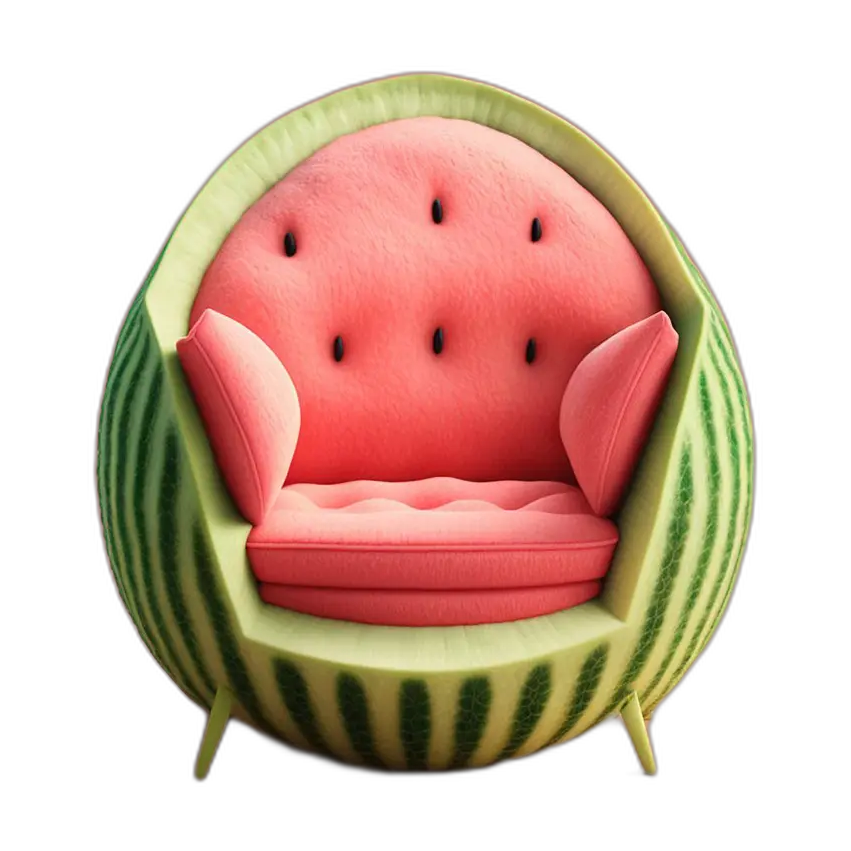

In [7]:
from PIL import Image
import torch
import os

processed_image = Image.open(PROCESSED_PATH).convert("RGBA")

print("Input image:", processed_image.size)
print("Image mode:", processed_image.mode)

display(processed_image)

  0%|          | 0/75 [00:00<?, ?it/s]

Generated views: 1


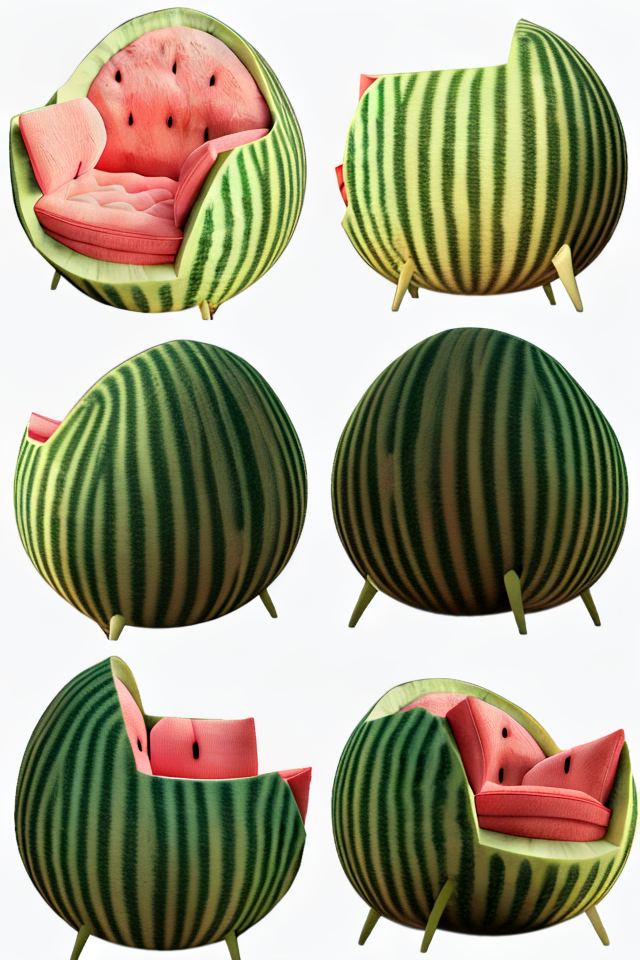

In [8]:
with torch.inference_mode():
    result = pipeline(
        processed_image,
        num_inference_steps=75
    )

generated_images = result.images

print("Generated views:", len(generated_images))
display(generated_images[0])

In [9]:
import numpy as np
import torch
from einops import rearrange

# Save contact sheet
CONTACT_PATH = f"{BASE_DIR}/outputs/zero123_contact_sheet.png"
os.makedirs(f"{BASE_DIR}/outputs", exist_ok=True)

generated_images[0].save(CONTACT_PATH)

# Convert contact sheet into six individual views
sheet = np.asarray(generated_images[0], dtype=np.float32) / 255.0

images = torch.from_numpy(sheet).permute(2, 0, 1).contiguous().float()

images = rearrange(
    images,
    'c (n h) (m w) -> (n m) c h w',
    n=3,
    m=2
)

print("Six views shape:", images.shape)
print("Saved contact sheet:", CONTACT_PATH)

Six views shape: torch.Size([6, 3, 320, 320])
Saved contact sheet: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_contact_sheet.png


In [10]:
from omegaconf import OmegaConf

config = OmegaConf.load(CONFIG_PATH)

model_config = config.model_config
infer_config = config.infer_config

print("===== MODEL CONFIGURATION =====")
print(OmegaConf.to_yaml(model_config))

print("===== INFERENCE CONFIGURATION =====")
print(OmegaConf.to_yaml(infer_config))

===== MODEL CONFIGURATION =====
target: src.models.lrm_mesh.InstantMesh
params:
  encoder_feat_dim: 768
  encoder_freeze: false
  encoder_model_name: facebook/dino-vitb16
  transformer_dim: 1024
  transformer_layers: 16
  transformer_heads: 16
  triplane_low_res: 32
  triplane_high_res: 64
  triplane_dim: 80
  rendering_samples_per_ray: 128
  grid_res: 128
  grid_scale: 2.1

===== INFERENCE CONFIGURATION =====
unet_path: ckpts/diffusion_pytorch_model.bin
model_path: ckpts/instant_mesh_large.ckpt
texture_resolution: 1024
render_resolution: 512



In [11]:
import torch
import transformers.pytorch_utils as pytorch_utils

def find_pruneable_heads_and_indices(
    heads, n_heads, head_size, already_pruned_heads
):
    mask = torch.ones(n_heads, head_size)
    heads = set(heads) - already_pruned_heads

    for head in heads:
        head -= sum(1 for h in already_pruned_heads if h < head)
        mask[head] = 0

    index = torch.arange(mask.numel())[mask.view(-1).bool()]
    return heads, index.long()

pytorch_utils.find_pruneable_heads_and_indices = (
    find_pruneable_heads_and_indices
)

from src.models.encoder.dino import ViTModel

def compatible_get_head_mask(self, head_mask, num_hidden_layers):
    if head_mask is None:
        return [None] * num_hidden_layers
    return self._convert_head_mask_to_5d(
        head_mask, num_hidden_layers
    )

ViTModel.get_head_mask = compatible_get_head_mask

print("DINO compatibility patches applied.")

DINO compatibility patches applied.


In [13]:
from omegaconf import OmegaConf
from src.utils.train_util import instantiate_from_config

config = OmegaConf.load(CONFIG_PATH)
model_config = config.model_config
infer_config = config.infer_config

device = torch.device("cuda")

model = instantiate_from_config(model_config)

checkpoint = torch.load(
    MODEL_CKPT,
    map_location="cpu",
    weights_only=False
)

state_dict = {
    k[14:]: v
    for k, v in checkpoint["state_dict"].items()
    if k.startswith("lrm_generator.")
    and "source_camera" not in k
}

load_result = model.load_state_dict(state_dict, strict=True)

del checkpoint, state_dict

print("InstantMesh checkpoint loaded.")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(
Some weights of ViTModel were not initialized from the model checkpoint at facebook/dino-vitb16 and are newly initialized: ['encoder.layer.0.adaLN_modulation.1.bias', 'encoder.layer.0.adaLN_modulation.1.weight', 'encoder.layer.1.adaLN_modulation.1.bias', 'encoder.layer.1.adaLN_modulation.1.weight', 'encoder.layer.10.adaLN_modulation.1.bias', 'encoder.layer.10.adaLN_modulation.1.weight', 'encoder.layer.11.adaLN_modulation.1.bias', 'encoder.layer.11.adaLN_modulation.1.weight', 'encoder.layer.2.adaLN_modulation.1.bias', 'enc

InstantMesh checkpoint loaded.
Missing keys: []
Unexpected keys: []


In [14]:
model.grid_res = 64

model = model.to(device)

model.init_flexicubes_geometry(
    device,
    fovy=30.0
)

model = model.eval()

print("InstantMesh ready.")
print("Grid resolution:", model.grid_res)
print("GPU memory:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

InstantMesh ready.
Grid resolution: 64
GPU memory: 5.05 GB


In [15]:
import torch
from einops import rearrange
from torchvision.transforms import v2
from src.utils.camera_util import get_zero123plus_input_cameras

# Prepare six generated views
input_images = images.unsqueeze(0).to(device)

input_images = v2.functional.resize(
    input_images,
    (320, 320),
    interpolation=3,
    antialias=True
).clamp(0, 1)

# Generate official Zero123++ camera parameters
input_cameras = get_zero123plus_input_cameras(
    batch_size=1,
    radius=4.0
).to(device)

print("Input images:", input_images.shape)
print("Camera parameters:", input_cameras.shape)
print("Image device:", input_images.device)
print("Camera device:", input_cameras.device)

Input images: torch.Size([1, 6, 3, 320, 320])
Camera parameters: torch.Size([1, 6, 16])
Image device: cuda:0
Camera device: cuda:0


In [16]:
with torch.inference_mode():
    planes = model.forward_planes(
        input_images,
        input_cameras
    )

print("Triplane shape:", planes.shape)
print(
    "GPU memory:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Triplane shape: torch.Size([1, 3, 80, 64, 64])
GPU memory: 5.06 GB


In [17]:
with torch.inference_mode():
    mesh_out = model.extract_mesh(
        planes,
        use_texture_map=False,
        render_resolution=infer_config.render_resolution
    )

print("Mesh extraction completed!")
print("Output type:", type(mesh_out))

Mesh extraction completed!
Output type: <class 'tuple'>


In [18]:
vertices, faces, vertex_colors = mesh_out[0]

print("Vertices:", vertices.shape)
print("Faces:", faces.shape)
print("Vertex colors:", vertex_colors.shape)

ValueError: too many values to unpack (expected 3)

In [19]:
print("Mesh output type:", type(mesh_out))
print("Number of outputs:", len(mesh_out))

print("\nFirst output type:", type(mesh_out[0]))
print("Number of elements:", len(mesh_out[0]))

for i, item in enumerate(mesh_out[0]):
    print(
        f"Element {i}:",
        type(item),
        getattr(item, "shape", None)
    )

Mesh output type: <class 'tuple'>
Number of outputs: 3

First output type: <class 'numpy.ndarray'>
Number of elements: 16740
Element 0: <class 'numpy.ndarray'> (3,)
Element 1: <class 'numpy.ndarray'> (3,)
Element 2: <class 'numpy.ndarray'> (3,)
Element 3: <class 'numpy.ndarray'> (3,)
Element 4: <class 'numpy.ndarray'> (3,)
Element 5: <class 'numpy.ndarray'> (3,)
Element 6: <class 'numpy.ndarray'> (3,)
Element 7: <class 'numpy.ndarray'> (3,)
Element 8: <class 'numpy.ndarray'> (3,)
Element 9: <class 'numpy.ndarray'> (3,)
Element 10: <class 'numpy.ndarray'> (3,)
Element 11: <class 'numpy.ndarray'> (3,)
Element 12: <class 'numpy.ndarray'> (3,)
Element 13: <class 'numpy.ndarray'> (3,)
Element 14: <class 'numpy.ndarray'> (3,)
Element 15: <class 'numpy.ndarray'> (3,)
Element 16: <class 'numpy.ndarray'> (3,)
Element 17: <class 'numpy.ndarray'> (3,)
Element 18: <class 'numpy.ndarray'> (3,)
Element 19: <class 'numpy.ndarray'> (3,)
Element 20: <class 'numpy.ndarray'> (3,)
Element 21: <class 'nump

In [20]:
vertices, faces, vertex_colors = mesh_out

print("Vertices:", vertices.shape)
print("Faces:", faces.shape)
print("Vertex colors:", vertex_colors.shape)

Vertices: (16740, 3)
Faces: (33460, 3)
Vertex colors: (16740, 3)


In [23]:
import trimesh

mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    vertex_colors=vertex_colors,
    process=False
)

print("Mesh created successfully!")

Mesh created successfully!


In [25]:
print("===== MESH VALIDATION =====")
print("Watertight:", mesh.is_watertight)
print("Winding consistent:", mesh.is_winding_consistent)
print("Degenerate faces:", len(mesh.degenerate_faces) if hasattr(mesh, "degenerate_faces") else "Check unavailable")
print("Vertex count:", len(mesh.vertices))
print("Face count:", len(mesh.faces))
print("Surface area:", mesh.area)
print("Volume:", mesh.volume)
print("Bounding box:\n", mesh.bounds)

===== MESH VALIDATION =====
Watertight: True
Winding consistent: True
Degenerate faces: Check unavailable
Vertex count: 16740
Face count: 33460
Surface area: 12.139260405613786
Volume: 2.662411335369493
Bounding box:
 [[-0.96192747 -0.95347488 -0.92345792]
 [ 0.90166521  0.95248908  0.935799  ]]


In [26]:
import onnxruntime as ort
import rembg

print("ONNX Runtime:", ort.__version__)
print("rembg imported successfully")

ONNX Runtime: 1.31.1
rembg imported successfully


In [27]:
from src.utils.infer_util import remove_background, resize_foreground
import inspect

print("remove_background:")
print(inspect.signature(remove_background))

print("\nresize_foreground:")
print(inspect.signature(resize_foreground))

remove_background:
(image: PIL.Image.Image, rembg_session: Any = None, force: bool = False, **rembg_kwargs) -> PIL.Image.Image

resize_foreground:
(image: PIL.Image.Image, ratio: float) -> PIL.Image.Image


In [28]:
import rembg
from PIL import Image
from src.utils.infer_util import remove_background, resize_foreground

# Load original input image
input_path = "/content/InstantMesh/examples/chair_watermelon.png"
input_image = Image.open(input_path).convert("RGB")

# Create background removal session
rembg_session = rembg.new_session()

# Remove background
input_image = remove_background(input_image, rembg_session)

# Resize foreground
input_image = resize_foreground(input_image, 0.85)

print("Preprocessing completed!")
print("Image size:", input_image.size)
print("Image mode:", input_image.mode)

display(input_image)

: 

: 

: 

In [1]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


Creating rembg session...
Loading image...
Removing background...
Background removal successful!


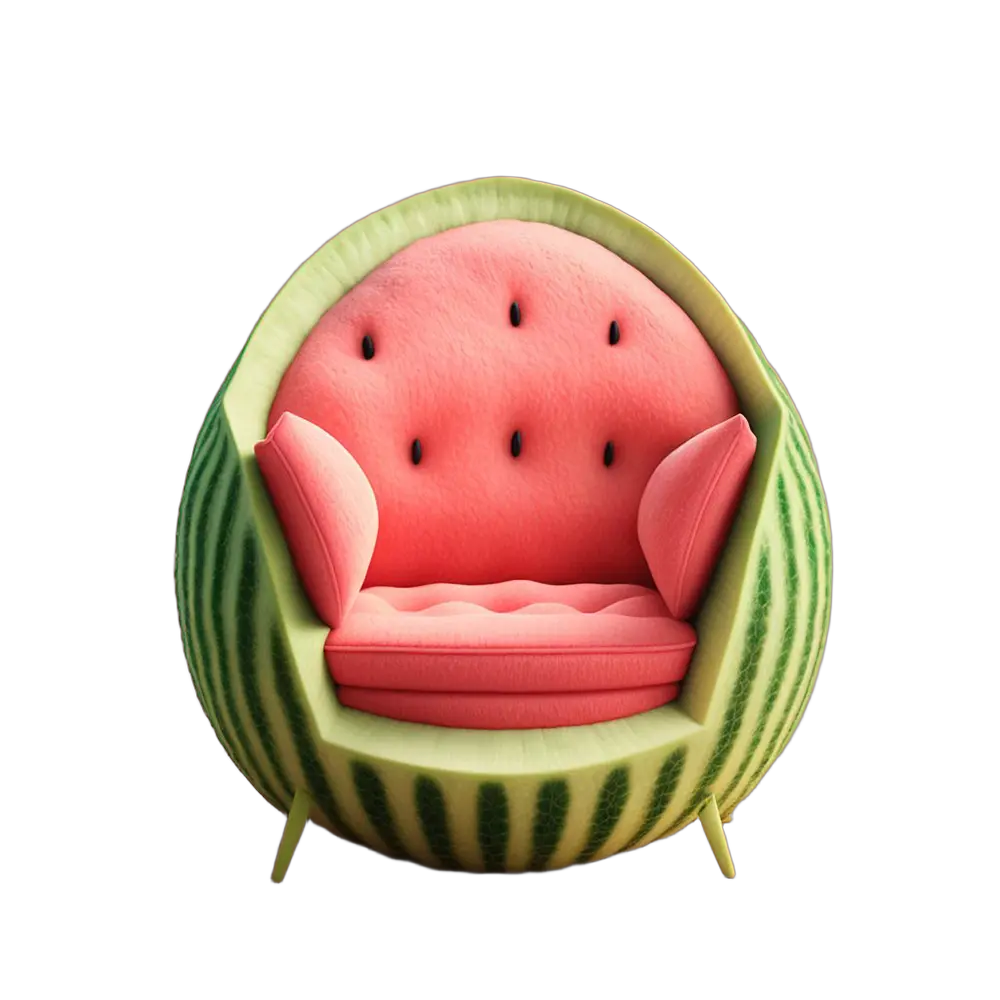

In [2]:
import rembg
from PIL import Image

print("Creating rembg session...")
session = rembg.new_session()

print("Loading image...")
image = Image.open(
    "/content/InstantMesh/examples/chair_watermelon.png"
).convert("RGB")

print("Removing background...")
result = rembg.remove(image, session=session)

print("Background removal successful!")
display(result)

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:
import os
import sys

REPO_DIR = "/content/InstantMesh"

os.chdir(REPO_DIR)

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

print("Working directory:", os.getcwd())
print("InstantMesh source exists:", os.path.exists("src"))

Working directory: /content/InstantMesh
InstantMesh source exists: True


In [6]:
BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

MODEL_DIR = f"{BASE_DIR}/models"
INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"

MODEL_CKPT = f"{INSTANTMESH_DIR}/instant_mesh_large.ckpt"
UNET_CKPT = f"{INSTANTMESH_DIR}/diffusion_pytorch_model.bin"

CONFIG_PATH = f"{REPO_DIR}/configs/instant-mesh-large.yaml"

print("InstantMesh checkpoint:", os.path.exists(MODEL_CKPT))
print("Custom UNet checkpoint:", os.path.exists(UNET_CKPT))
print("Config:", os.path.exists(CONFIG_PATH))

InstantMesh checkpoint: True
Custom UNet checkpoint: True
Config: True


In [7]:
import torch
import numpy as np
import rembg

from PIL import Image
from src.utils.infer_util import remove_background, resize_foreground

print("Preprocessing imports successful!")
print("GPU:", torch.cuda.get_device_name(0))

Preprocessing imports successful!
GPU: Tesla T4


In [8]:
input_path = "/content/InstantMesh/examples/chair_watermelon.png"

image = Image.open(input_path).convert("RGB")

session = rembg.new_session()

result = remove_background(image, session)
processed_image = resize_foreground(result, 0.85)

print("Preprocessing complete!")
display(processed_image)

: 

: 

: 

In [1]:
import torch
import psutil
import os

# System RAM
ram = psutil.virtual_memory()

print("===== SYSTEM RAM =====")
print("Total:", round(ram.total / 1024**3, 2), "GB")
print("Available:", round(ram.available / 1024**3, 2), "GB")
print("Used:", round(ram.percent, 2), "%")

# GPU memory
print("\n===== GPU MEMORY =====")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Allocated:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
    print("Reserved:", round(torch.cuda.memory_reserved() / 1024**3, 2), "GB")
    print("Total:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

===== SYSTEM RAM =====
Total: 12.67 GB
Available: 10.02 GB
Used: 20.9 %

===== GPU MEMORY =====
GPU: Tesla T4
Allocated: 0.0 GB
Reserved: 0.0 GB
Total: 14.56 GB


In [2]:
import numpy as np
import PIL
import transformers
import diffusers
import huggingface_hub
import onnxruntime
import rembg
import trimesh
import torch

print("===== PACKAGE VERSIONS =====")
print("PyTorch:", torch.__version__)
print("NumPy:", np.__version__)
print("Pillow:", PIL.__version__)
print("Transformers:", transformers.__version__)
print("Diffusers:", diffusers.__version__)
print("HuggingFace Hub:", huggingface_hub.__version__)
print("ONNX Runtime:", onnxruntime.__version__)
print("rembg:", rembg.__version__ if hasattr(rembg, "__version__") else "Imported")
print("Trimesh:", trimesh.__version__)

===== PACKAGE VERSIONS =====
PyTorch: 2.11.0+cu130
NumPy: 2.5.4
Pillow: 13.0.0
Transformers: 4.57.1
Diffusers: 0.35.2
HuggingFace Hub: 0.36.2
ONNX Runtime: 1.31.1
rembg: 2.0.86
Trimesh: 5.2.0


ONNX providers: ['AzureExecutionProvider', 'CPUExecutionProvider']
Image loaded: (1000, 1000)
Background removal successful!
Result size: (1000, 1000)


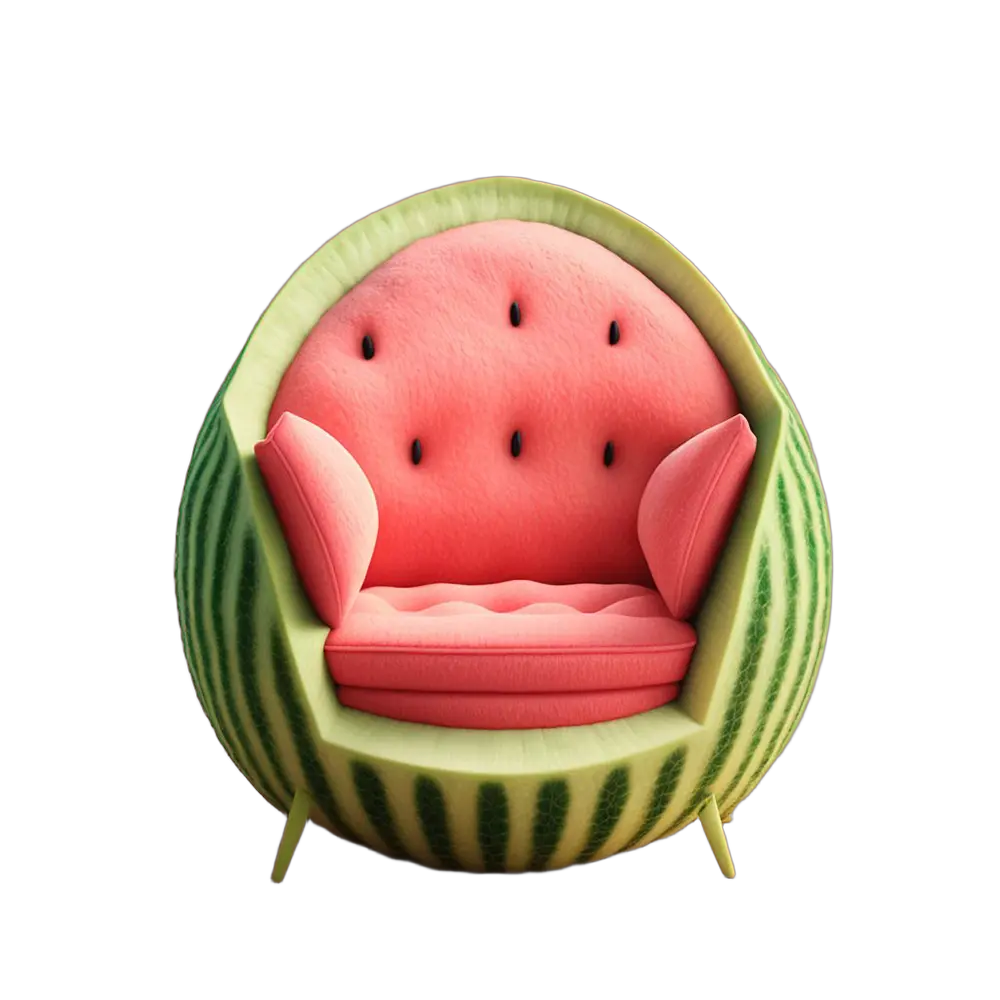

In [3]:
import rembg
import onnxruntime as ort
from PIL import Image
import numpy as np

print("ONNX providers:", ort.get_available_providers())

session = rembg.new_session()

image = Image.open(
    "/content/InstantMesh/examples/chair_watermelon.png"
).convert("RGB")

print("Image loaded:", image.size)

result = rembg.remove(image, session=session)

print("Background removal successful!")
print("Result size:", result.size)

display(result)

In [4]:
from src.utils.infer_util import resize_foreground

processed_image = resize_foreground(result, 0.85)

print("Processed image:", processed_image.size)
display(processed_image)

ModuleNotFoundError: No module named 'src'

In [5]:
import os
import sys

REPO_DIR = "/content/InstantMesh"

# Check whether repository exists
print("Repository exists:", os.path.exists(REPO_DIR))

# Set working directory
os.chdir(REPO_DIR)

# Add repository to Python path
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

print("Current directory:", os.getcwd())
print("src directory exists:", os.path.isdir("src"))

Repository exists: True
Current directory: /content/InstantMesh
src directory exists: True


Foreground resizing successful!


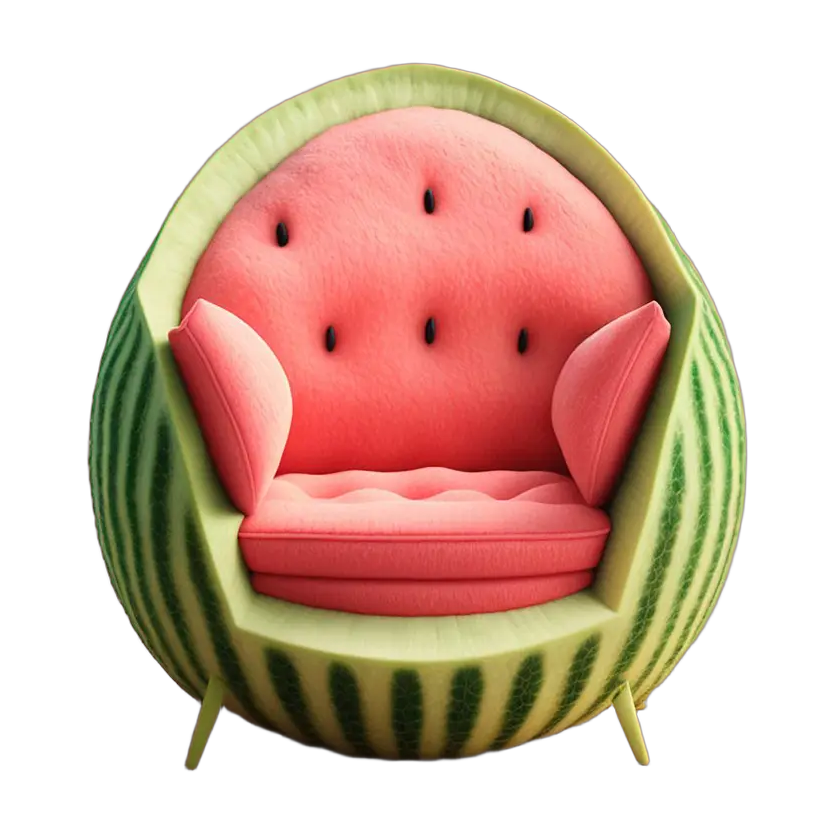

In [6]:
from src.utils.infer_util import resize_foreground

processed_image = resize_foreground(result, 0.85)

print("Foreground resizing successful!")
display(processed_image)

In [7]:
import os
import torch

BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"
MODEL_DIR = f"{BASE_DIR}/models"
INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"

UNET_CKPT = f"{INSTANTMESH_DIR}/diffusion_pytorch_model.bin"

print("UNet checkpoint exists:", os.path.exists(UNET_CKPT))

if os.path.exists(UNET_CKPT):
    print(
        "Checkpoint size:",
        round(os.path.getsize(UNET_CKPT) / (1024**3), 2),
        "GB"
    )

UNet checkpoint exists: True
Checkpoint size: 1.61 GB


In [8]:
print("Pipeline exists:", "pipeline" in globals())

if "pipeline" in globals():
    print("UNet device:", next(pipeline.unet.parameters()).device)

Pipeline exists: False


In [9]:
import torch
import os
from diffusers import DiffusionPipeline, EulerAncestralDiscreteScheduler

SNAPSHOT_DIR = (
    "/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/"
    "models--sudo-ai--zero123plus-v1.2/snapshots/"
    "2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

print("Snapshot exists:", os.path.exists(SNAPSHOT_DIR))
print("GPU:", torch.cuda.get_device_name(0))
print("CUDA available:", torch.cuda.is_available())

Snapshot exists: True
GPU: Tesla T4
CUDA available: True


In [10]:
import torch
from diffusers import DiffusionPipeline, EulerAncestralDiscreteScheduler

pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline="/content/InstantMesh/zero123plus",
    torch_dtype=torch.float16,
    trust_remote_code=True,
    local_files_only=True
)

# Match the official InstantMesh scheduler
pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

# Move pipeline to GPU
pipeline = pipeline.to("cuda")

print("Zero123++ loaded successfully!")
print("Scheduler:", type(pipeline.scheduler).__name__)
print("GPU:", next(pipeline.unet.parameters()).device)

Keyword arguments {'trust_remote_code': True} are not expected by Zero123PlusPipeline and will be ignored.


Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

: 

: 

: 

In [1]:
import os
import sys
import torch
import psutil
import numpy as np
import transformers
import diffusers
import huggingface_hub
import onnxruntime

print("===== RUNTIME DIAGNOSTICS =====")
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("NumPy:", np.__version__)
print("Transformers:", transformers.__version__)
print("Diffusers:", diffusers.__version__)
print("HuggingFace Hub:", huggingface_hub.__version__)
print("ONNX Runtime:", onnxruntime.__version__)

ram = psutil.virtual_memory()
print("\nRAM available:", round(ram.available / 1024**3, 2), "GB")

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU memory:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

===== RUNTIME DIAGNOSTICS =====
Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA: True
NumPy: 2.5.4
Transformers: 4.57.1
Diffusers: 0.35.2
HuggingFace Hub: 0.36.2
ONNX Runtime: 1.31.1

RAM available: 9.94 GB
GPU: Tesla T4
GPU memory: 14.56 GB


In [3]:
SNAPSHOT_DIR = (
    "/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/"
    "models--sudo-ai--zero123plus-v1.2/snapshots/"
    "2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

In [4]:
import os
import sys
import torch

REPO_DIR = "/content/InstantMesh"

os.chdir(REPO_DIR)
sys.path.insert(0, REPO_DIR)

from diffusers import DiffusionPipeline

print("DiffusionPipeline:", DiffusionPipeline)
print("CUDA:", torch.cuda.is_available())
print("Snapshot exists:", os.path.exists(SNAPSHOT_DIR))
print("Custom pipeline exists:", os.path.exists(
    "/content/InstantMesh/zero123plus"
))

DiffusionPipeline: <class 'diffusers.pipelines.pipeline_utils.DiffusionPipeline'>
CUDA: True
Snapshot exists: True
Custom pipeline exists: True


In [5]:
import os

PIPELINE_FILE = "/content/InstantMesh/zero123plus/pipeline.py"

print("Pipeline file exists:", os.path.exists(PIPELINE_FILE))

if os.path.exists(PIPELINE_FILE):
    with open(PIPELINE_FILE, "r") as f:
        content = f.read()

    print(content[:6000])

Pipeline file exists: True
from typing import Any, Dict, Optional
from diffusers.models import AutoencoderKL, UNet2DConditionModel
from diffusers.schedulers import KarrasDiffusionSchedulers

import numpy
import torch
import torch.nn as nn
import torch.utils.checkpoint
import torch.distributed
import transformers
from collections import OrderedDict
from PIL import Image
from torchvision import transforms
from transformers import CLIPImageProcessor, CLIPTextModel, CLIPTokenizer

import diffusers
from diffusers import (
    AutoencoderKL,
    DDPMScheduler,
    DiffusionPipeline,
    EulerAncestralDiscreteScheduler,
    UNet2DConditionModel,
    ImagePipelineOutput
)
from diffusers.image_processor import VaeImageProcessor
from diffusers.models.attention_processor import Attention, AttnProcessor, XFormersAttnProcessor, AttnProcessor2_0
from diffusers.utils.import_utils import is_xformers_available


def to_rgb_image(maybe_rgba: Image.Image):
    if maybe_rgba.mode == 'RGB':
        return 

In [6]:
with open(PIPELINE_FILE, "r") as f:
    lines = f.readlines()

keywords = [
    "class Zero123PlusPipeline",
    "def __init__",
    "def __call__",
    "def encode_image",
    "register_modules"
]

for i, line in enumerate(lines):
    if any(keyword in line for keyword in keywords):
        print(f"\n--- Line {i + 1} ---")
        print("".join(lines[i:i+35]))


--- Line 44 ---
    def __init__(
        self,
        chained_proc,
        enabled=False,
        name=None
    ) -> None:
        super().__init__()
        self.enabled = enabled
        self.chained_proc = chained_proc
        self.name = name

    def __call__(
        self, attn: Attention, hidden_states, encoder_hidden_states=None, attention_mask=None,
        mode="w", ref_dict: dict = None, is_cfg_guidance = False
    ) -> Any:
        if encoder_hidden_states is None:
            encoder_hidden_states = hidden_states
        if self.enabled and is_cfg_guidance:
            res0 = self.chained_proc(attn, hidden_states[:1], encoder_hidden_states[:1], attention_mask)
            hidden_states = hidden_states[1:]
            encoder_hidden_states = encoder_hidden_states[1:]
        if self.enabled:
            if mode == 'w':
                ref_dict[self.name] = encoder_hidden_states
            elif mode == 'r':
                encoder_hidden_states = torch.cat([encoder_hidd

In [7]:
def prepare(self):
    train_sched = DDPMScheduler.from_config(self.scheduler.config)

    if isinstance(self.unet, UNet2DConditionModel):
        self.unet = RefOnlyNoisedUNet(
            self.unet, train_sched, self.scheduler
        ).eval()

In [9]:
import os
import sys
import torch

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import os
import sys
import torch
from diffusers import DiffusionPipeline

REPO_DIR = "/content/InstantMesh"
os.chdir(REPO_DIR)

if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

SNAPSHOT_DIR = (
    "/content/drive/MyDrive/Sketch2Shape_AI/models/zero123plus/"
    "models--sudo-ai--zero123plus-v1.2/snapshots/"
    "2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

print("Repository:", os.getcwd())
print("Snapshot exists:", os.path.exists(SNAPSHOT_DIR))
print("CUDA:", torch.cuda.is_available())

Repository: /content/InstantMesh
Snapshot exists: True
CUDA: True


In [13]:
pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline="/content/InstantMesh/zero123plus",
    torch_dtype=torch.float16,
    local_files_only=True
)

print("Zero123++ loaded successfully!")
print("UNet device:", next(pipeline.unet.parameters()).device)
print("UNet type:", type(pipeline.unet).__name__)

Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!


Zero123++ loaded successfully!
UNet device: cpu
UNet type: UNet2DConditionModel


In [14]:
import os
import torch

UNET_CKPT = (
    "/content/drive/MyDrive/Sketch2Shape_AI/"
    "models/instantmesh/diffusion_pytorch_model.bin"
)

print("Checkpoint exists:", os.path.exists(UNET_CKPT))

state_dict = torch.load(
    UNET_CKPT,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint loaded!")
print("Number of parameters:", len(state_dict))

Checkpoint exists: True
Checkpoint loaded!
Number of parameters: 686


In [15]:
load_result = pipeline.unet.load_state_dict(
    state_dict,
    strict=True
)

print("Custom UNet weights loaded successfully!")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

del state_dict

print("UNet device:", next(pipeline.unet.parameters()).device)


Custom UNet weights loaded successfully!
Missing keys: []
Unexpected keys: []
UNet device: cpu


In [16]:
from diffusers import EulerAncestralDiscreteScheduler

pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

print("Scheduler:", type(pipeline.scheduler).__name__)
print("Timestep spacing:", pipeline.scheduler.config.timestep_spacing)
print("UNet device:", next(pipeline.unet.parameters()).device)

Scheduler: EulerAncestralDiscreteScheduler
Timestep spacing: trailing
UNet device: cpu


In [17]:
import torch

pipeline = pipeline.to("cuda")

print("Pipeline moved to GPU!")
print("UNet device:", next(pipeline.unet.parameters()).device)
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Pipeline moved to GPU!
UNet device: cuda:0
GPU memory allocated: 3.6 GB


In [18]:
import torch

total = torch.cuda.get_device_properties(0).total_memory
allocated = torch.cuda.memory_allocated(0)
reserved = torch.cuda.memory_reserved(0)
free, total_nvidia = torch.cuda.mem_get_info(0)

print("===== GPU MEMORY STATUS =====")
print(f"Total VRAM:     {total / 1024**3:.2f} GB")
print(f"Allocated:      {allocated / 1024**3:.2f} GB")
print(f"Reserved:       {reserved / 1024**3:.2f} GB")
print(f"Currently free: {free / 1024**3:.2f} GB")
print(f"Used by others: {(total_nvidia-free-allocated) / 1024**3:.2f} GB")

===== GPU MEMORY STATUS =====
Total VRAM:     14.56 GB
Allocated:      3.60 GB
Reserved:       3.76 GB
Currently free: 10.70 GB
Used by others: 0.26 GB


Processed image ready: (835, 835)


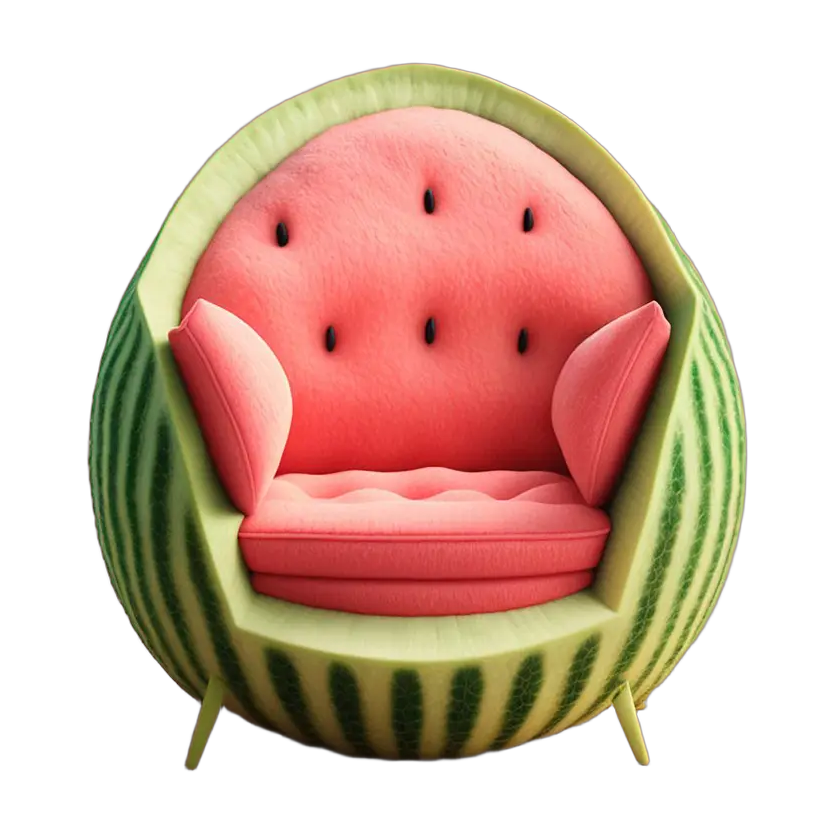

In [20]:
import rembg
from PIL import Image
from src.utils.infer_util import remove_background, resize_foreground

input_path = "/content/InstantMesh/examples/chair_watermelon.png"

image = Image.open(input_path).convert("RGB")

session = rembg.new_session()
result = remove_background(image, session)

processed_image = resize_foreground(result, 0.85)

print("Processed image ready:", processed_image.size)
display(processed_image)

In [21]:
import torch

with torch.inference_mode():
    result = pipeline(
        processed_image,
        num_inference_steps=75
    )

generated_images = result.images

print("Generated views:", len(generated_images))

display(generated_images[0])

: 

: 

: 

In [1]:
%pip install -q \
    numpy==2.1.3 \
    Pillow==11.3.0 \
    transformers==4.57.1 \
    diffusers==0.35.2 \
    huggingface_hub==0.36.2 \
    onnxruntime==1.31.1 \
    rembg==2.0.86 \
    trimesh==5.2.0 \
    xatlas \
    einops \
    omegaconf \
    accelerate

ERROR: Cannot install numpy==2.1.3, rembg==2.0.86 and transformers==4.57.1 because these package versions have conflicting dependencies.
ERROR: ResolutionImpossible: for help visit https://pip.pypa.io/en/latest/topics/dependency-resolution/#dealing-with-dependency-conflicts


In [2]:
from google.colab import drive
drive.mount("/content/drive")

import os
import sys

REPO_DIR = "/content/InstantMesh"

if not os.path.exists(REPO_DIR):
    !git clone https://github.com/TencentARC/InstantMesh.git {REPO_DIR}

os.chdir(REPO_DIR)
sys.path.insert(0, REPO_DIR)

print("Repository:", os.getcwd())
print("Repository ready:", os.path.exists("src"))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Repository: /content/InstantMesh
Repository ready: True


In [3]:
BASE_DIR = "/content/drive/MyDrive/Sketch2Shape_AI"

MODEL_DIR = f"{BASE_DIR}/models"
INSTANTMESH_DIR = f"{MODEL_DIR}/instantmesh"
ZERO123_DIR = f"{MODEL_DIR}/zero123plus"

MODEL_CKPT = f"{INSTANTMESH_DIR}/instant_mesh_large.ckpt"
UNET_CKPT = f"{INSTANTMESH_DIR}/diffusion_pytorch_model.bin"

CONFIG_PATH = f"{REPO_DIR}/configs/instant-mesh-large.yaml"

SNAPSHOT_DIR = (
    ZERO123_DIR
    + "/models--sudo-ai--zero123plus-v1.2/snapshots/"
    + "2da07e89919e1a130c9b5add1584c70c7aa065fd"
)

print("InstantMesh checkpoint:", os.path.exists(MODEL_CKPT))
print("Custom UNet:", os.path.exists(UNET_CKPT))
print("Zero123++ snapshot:", os.path.exists(SNAPSHOT_DIR))
print("Config:", os.path.exists(CONFIG_PATH))

InstantMesh checkpoint: True
Custom UNet: True
Zero123++ snapshot: True
Config: True


In [4]:
import torch
import numpy as np
import PIL
import transformers
import diffusers
import huggingface_hub
import rembg
import trimesh
import onnxruntime

print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))

print("NumPy:", np.__version__)
print("Pillow:", PIL.__version__)
print("Transformers:", transformers.__version__)
print("Diffusers:", diffusers.__version__)
print("HuggingFace Hub:", huggingface_hub.__version__)
print("Trimesh:", trimesh.__version__)
print("ONNX Runtime:", onnxruntime.__version__)

print("Environment verification complete!")

PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4
NumPy: 2.5.4
Pillow: 13.0.0
Transformers: 4.57.1
Diffusers: 0.35.2
HuggingFace Hub: 0.36.2
Trimesh: 5.2.0
ONNX Runtime: 1.31.1
Environment verification complete!


In [5]:
session = rembg.new_session("u2net")

In [6]:
import torch
import transformers.pytorch_utils as pytorch_utils

def find_pruneable_heads_and_indices(
    heads, n_heads, head_size, already_pruned_heads
):
    mask = torch.ones(n_heads, head_size)
    heads = set(heads) - already_pruned_heads

    for head in heads:
        head -= sum(1 for h in already_pruned_heads if h < head)
        mask[head] = 0

    index = torch.arange(mask.numel())[mask.view(-1).bool()]
    return heads, index.long()

pytorch_utils.find_pruneable_heads_and_indices = (
    find_pruneable_heads_and_indices
)

from src.models.encoder.dino import ViTModel

def compatible_get_head_mask(self, head_mask, num_hidden_layers):
    if head_mask is None:
        return [None] * num_hidden_layers
    return self._convert_head_mask_to_5d(
        head_mask, num_hidden_layers
    )

ViTModel.get_head_mask = compatible_get_head_mask

print("InstantMesh DINO compatibility restored!")

InstantMesh DINO compatibility restored!


Preprocessing complete: (851, 851)


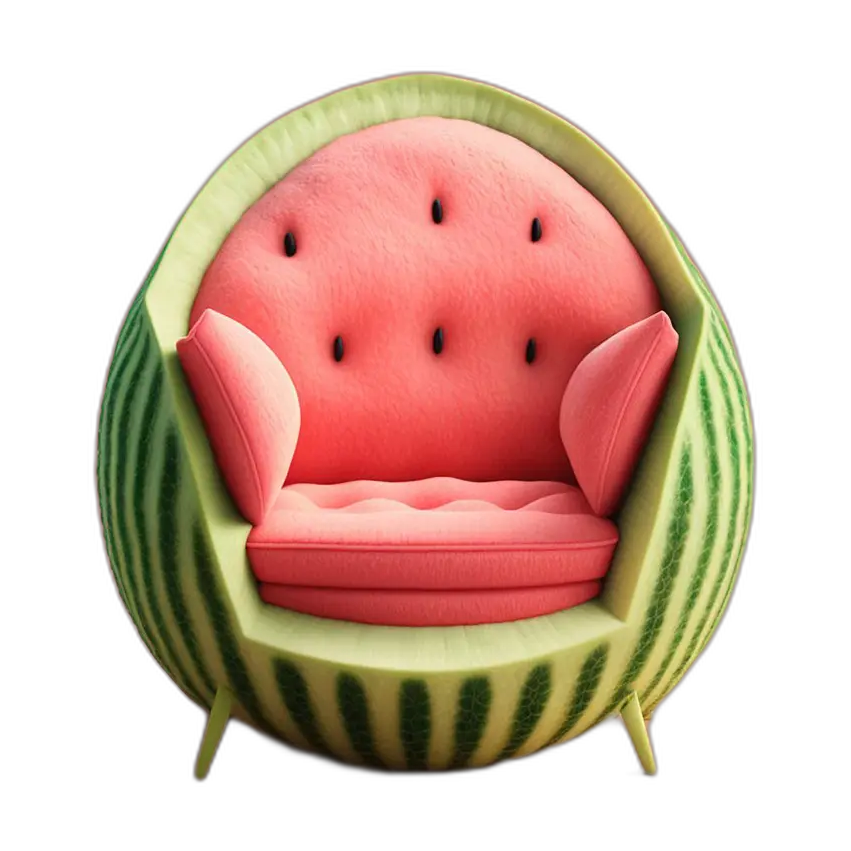

In [7]:
import rembg
from PIL import Image

session = rembg.new_session("u2net")

image = Image.open(
    "/content/InstantMesh/examples/chair_watermelon.png"
).convert("RGB")

result = rembg.remove(image, session=session)

from src.utils.infer_util import resize_foreground

processed_image = resize_foreground(result, 0.85)

print("Preprocessing complete:", processed_image.size)
display(processed_image)

In [8]:
import gc
import torch

del session
del image
del result

gc.collect()
torch.cuda.empty_cache()

free, total = torch.cuda.mem_get_info()

print("Free VRAM:", round(free / 1024**3, 2), "GB")
print("Total VRAM:", round(total / 1024**3, 2), "GB")
print("Processed image retained:", processed_image.size)

Free VRAM: 14.46 GB
Total VRAM: 14.56 GB
Processed image retained: (851, 851)


In [9]:
from diffusers import DiffusionPipeline, EulerAncestralDiscreteScheduler

pipeline = DiffusionPipeline.from_pretrained(
    SNAPSHOT_DIR,
    custom_pipeline=f"{REPO_DIR}/zero123plus",
    dtype=torch.float16,
    local_files_only=True
)

print("Zero123++ loaded!")
print("UNet device:", next(pipeline.unet.parameters()).device)

Keyword arguments {'dtype': torch.float16} are not expected by Zero123PlusPipeline and will be ignored.


Loading pipeline components...:   0%|          | 0/8 [00:00<?, ?it/s]

Zero123++ loaded!
UNet device: cpu


In [10]:
print("UNet device:", next(pipeline.unet.parameters()).device)
print("UNet dtype:", next(pipeline.unet.parameters()).dtype)

UNet device: cpu
UNet dtype: torch.float32


In [11]:
state_dict = torch.load(
    UNET_CKPT,
    map_location="cpu",
    weights_only=True
)

load_result = pipeline.unet.load_state_dict(
    state_dict,
    strict=True
)

print("Custom UNet loaded!")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

del state_dict
gc.collect()

Custom UNet loaded!
Missing keys: []
Unexpected keys: []


97

In [12]:
print("UNet device:", next(pipeline.unet.parameters()).device)
print("UNet dtype:", next(pipeline.unet.parameters()).dtype)
print("VAE dtype:", next(pipeline.vae.parameters()).dtype)
print("Vision encoder dtype:", next(pipeline.vision_encoder.parameters()).dtype)

UNet device: cpu
UNet dtype: torch.float32
VAE dtype: torch.float32
Vision encoder dtype: torch.float32


In [13]:
from diffusers import EulerAncestralDiscreteScheduler

pipeline.scheduler = EulerAncestralDiscreteScheduler.from_config(
    pipeline.scheduler.config,
    timestep_spacing="trailing"
)

print("Scheduler:", type(pipeline.scheduler).__name__)
print("Timestep spacing:", pipeline.scheduler.config.timestep_spacing)

Scheduler: EulerAncestralDiscreteScheduler
Timestep spacing: trailing


In [14]:
import torch
import gc

gc.collect()
torch.cuda.empty_cache()

pipeline = pipeline.to(
    device="cuda",
    dtype=torch.float16
)

print("===== MODEL STATUS =====")
print("UNet:", next(pipeline.unet.parameters()).dtype)
print("VAE:", next(pipeline.vae.parameters()).dtype)
print("Vision encoder:", next(pipeline.vision_encoder.parameters()).dtype)

free, total = torch.cuda.mem_get_info()

print("\n===== GPU MEMORY =====")
print("Allocated:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")
print("Free:", round(free / 1024**3, 2), "GB")
print("Total:", round(total / 1024**3, 2), "GB")

===== MODEL STATUS =====
UNet: torch.float16
VAE: torch.float16
Vision encoder: torch.float16

===== GPU MEMORY =====
Allocated: 3.6 GB
Free: 10.7 GB
Total: 14.56 GB


  0%|          | 0/75 [00:00<?, ?it/s]

Number of generated images: 1
Contact sheet size: (640, 960)


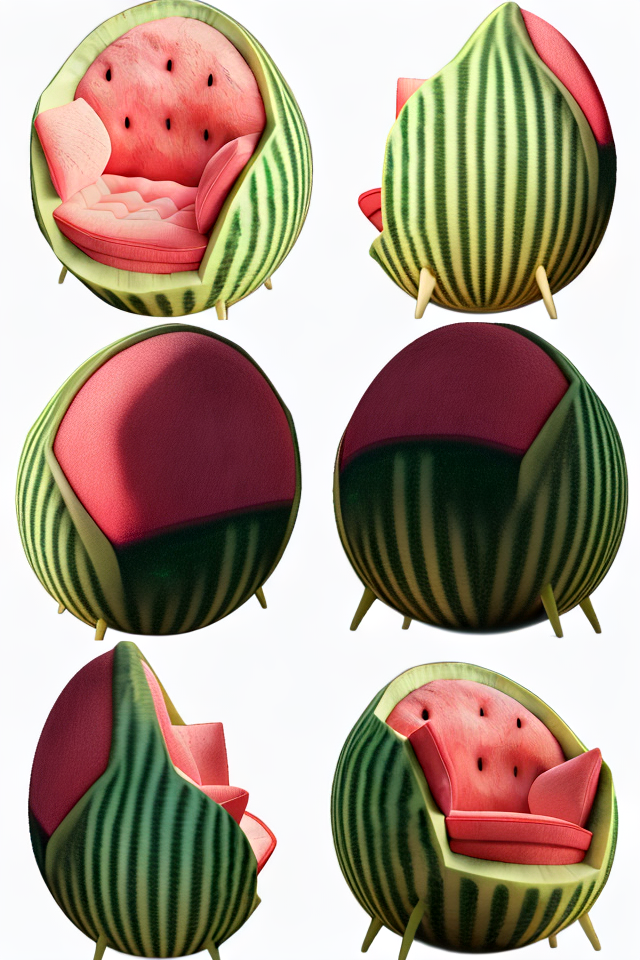

In [15]:
import torch

with torch.inference_mode():
    result = pipeline(
        processed_image,
        num_inference_steps=75
    )

generated_images = result.images

print("Number of generated images:", len(generated_images))
print("Contact sheet size:", generated_images[0].size)

display(generated_images[0])

In [17]:
import os

from PIL import Image

OUTPUT_DIR = f"{BASE_DIR}/outputs/zero123_views"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save complete contact sheet
generated_images[0].save(
    f"{OUTPUT_DIR}/contact_sheet.png"
)

# Split into six individual views (3 rows x 2 columns)
sheet = generated_images[0]

w, h = sheet.size
view_w = w // 2
view_h = h // 3

for i in range(6):
    row = i // 2
    col = i % 2

    view = sheet.crop((
        col * view_w,
        row * view_h,
        (col + 1) * view_w,
        (row + 1) * view_h
    ))

    view.save(f"{OUTPUT_DIR}/view_{i+1}.png")

print("All six views saved!")
print("Output directory:", OUTPUT_DIR)
print("Files:", os.listdir(OUTPUT_DIR))

All six views saved!
Output directory: /content/drive/MyDrive/Sketch2Shape_AI/outputs/zero123_views
Files: ['contact_sheet.png', 'view_1.png', 'view_2.png', 'view_3.png', 'view_4.png', 'view_5.png', 'view_6.png']


In [18]:
import gc
import torch

# Release Zero123++ and temporary image objects
del pipeline
del generated_images
del result
del processed_image

# Garbage collection
gc.collect()

# Clear unused GPU memory
torch.cuda.empty_cache()
torch.cuda.ipc_collect()

# Check memory
free, total = torch.cuda.mem_get_info()

print("===== MEMORY AFTER ZERO123++ =====")
print("Free VRAM:", round(free / 1024**3, 2), "GB")
print("Total VRAM:", round(total / 1024**3, 2), "GB")
print("Allocated:", round(
    torch.cuda.memory_allocated() / 1024**3, 2
), "GB")

===== MEMORY AFTER ZERO123++ =====
Free VRAM: 14.36 GB
Total VRAM: 14.56 GB
Allocated: 0.01 GB


In [19]:
import torch
import os
import sys
import gc

from omegaconf import OmegaConf
from src.utils.train_util import instantiate_from_config

# Load configuration
config = OmegaConf.load(CONFIG_PATH)

model_config = config.model_config
infer_config = config.infer_config

print("Configuration loaded!")
print("Grid resolution:", model_config.params.grid_res)
print("Transformer dimension:", model_config.params.transformer_dim)
print("Transformer layers:", model_config.params.transformer_layers)
print("Inference configuration:")
print(OmegaConf.to_yaml(infer_config))

Configuration loaded!
Grid resolution: 128
Transformer dimension: 1024
Transformer layers: 16
Inference configuration:
unet_path: ckpts/diffusion_pytorch_model.bin
model_path: ckpts/instant_mesh_large.ckpt
texture_resolution: 1024
render_resolution: 512



In [20]:
# Instantiate reconstruction model
model = instantiate_from_config(model_config)

# Load pretrained InstantMesh checkpoint
checkpoint = torch.load(
    MODEL_CKPT,
    map_location="cpu",
    weights_only=False
)

state_dict = {
    k[14:]: v
    for k, v in checkpoint["state_dict"].items()
    if k.startswith("lrm_generator.")
    and "source_camera" not in k
}

load_result = model.load_state_dict(state_dict, strict=True)

print("InstantMesh checkpoint loaded!")
print("Missing keys:", load_result.missing_keys)
print("Unexpected keys:", load_result.unexpected_keys)

del checkpoint, state_dict
gc.collect()

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:104: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
You are not authenticated with the Hugging Face Hub in this notebook.
If the error persists, please let us know by opening an issue on GitHub (https://github.com/huggingface/huggingface_hub/issues/new).
  warnings.warn(
Some weights of ViTModel were not initialized from the model checkpoint at facebook/dino-vitb16 and are newly initialized: ['encoder.layer.0.adaLN_modulation.1.bias', 'encoder.layer.0.adaLN_modulation.1.weight', 'encoder.layer.1.adaLN_modulation.1.bias', 'encoder.layer.1.adaLN_modulation.1.weight', 'encoder.layer.10.adaLN_modulation.1.bias', 'encoder.layer.10.adaLN_modulation.1.weight', 'encoder.layer.11.adaLN_modulation.1.bias', 'encoder.layer.11.adaLN_modulation.1.weight', 'encoder.layer.2.adaLN_modulation.1.bias', 'enc

InstantMesh checkpoint loaded!
Missing keys: []
Unexpected keys: []


48

In [21]:
device = torch.device("cuda")

# Move model to GPU
model = model.to(device)
model = model.eval()

# Reduce geometry resolution for T4
model.grid_res = 64

# Initialize FlexiCubes geometry
model.init_flexicubes_geometry(
    device,
    fovy=30.0
)

print("InstantMesh initialized!")
print("Device:", device)
print("Grid resolution:", model.grid_res)
print("Vertices in grid:", model.geometry.verts.shape)
print("Grid cells:", model.geometry.indices.shape)

free, total = torch.cuda.mem_get_info()

print("\nFree VRAM:", round(free / 1024**3, 2), "GB")
print("Allocated:", round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

InstantMesh initialized!
Device: cuda
Grid resolution: 64
Vertices in grid: torch.Size([274625, 3])
Grid cells: torch.Size([262144, 8])

Free VRAM: 12.73 GB
Allocated: 1.45 GB


In [22]:
import numpy as np
import torch
from PIL import Image
from einops import rearrange
from torchvision.transforms import v2
from src.utils.camera_util import get_zero123plus_input_cameras

VIEWS_DIR = f"{BASE_DIR}/outputs/zero123_views"

# Load contact sheet
sheet = Image.open(
    f"{VIEWS_DIR}/contact_sheet.png"
).convert("RGB")

# Convert to tensor
images = np.asarray(sheet, dtype=np.float32) / 255.0

images = torch.from_numpy(images).permute(2, 0, 1).contiguous().float()

# Split into six views: 3 rows x 2 columns
images = rearrange(
    images,
    'c (n h) (m w) -> (n m) c h w',
    n=3,
    m=2
)

# Prepare batch
input_images = images.unsqueeze(0).to(device)

input_images = v2.functional.resize(
    input_images,
    (320, 320),
    interpolation=3,
    antialias=True
).clamp(0, 1)

# Prepare cameras
input_cameras = get_zero123plus_input_cameras(
    batch_size=1,
    radius=4.0
).to(device)

print("Input images:", input_images.shape)
print("Input cameras:", input_cameras.shape)
print("Image range:", input_images.min().item(), input_images.max().item())

Input images: torch.Size([1, 6, 3, 320, 320])
Input cameras: torch.Size([1, 6, 16])
Image range: 0.0 1.0


In [23]:
torch.cuda.empty_cache()

with torch.inference_mode():
    planes = model.forward_planes(
        input_images,
        input_cameras
    )

print("Triplane generation successful!")
print("Planes shape:", planes.shape)

print(
    "GPU allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

Triplane generation successful!
Planes shape: torch.Size([1, 3, 80, 64, 64])
GPU allocated: 1.46 GB


In [24]:
torch.cuda.empty_cache()

with torch.inference_mode():
    mesh_out = model.extract_mesh(
        planes,
        use_texture_map=False,
        **infer_config
    )

vertices, faces, vertex_colors = mesh_out

print("===== MESH EXTRACTION =====")
print("Vertices:", vertices.shape)
print("Faces:", faces.shape)
print("Vertex colors:", vertex_colors.shape)

print("\nGPU allocated:",
      round(torch.cuda.memory_allocated() / 1024**3, 2), "GB")

===== MESH EXTRACTION =====
Vertices: (16094, 3)
Faces: (32100, 3)
Vertex colors: (16094, 3)

GPU allocated: 1.46 GB


In [25]:
import numpy as np

print("Vertices dtype:", vertices.dtype)
print("Faces dtype:", faces.dtype)
print("Colors dtype:", vertex_colors.dtype)

print("\nVertex range:")
print("Min:", vertices.min())
print("Max:", vertices.max())

print("\nColor range:")
print("Min:", vertex_colors.min())
print("Max:", vertex_colors.max())

print("\nNaN in vertices:", np.isnan(vertices).any())
print("NaN in colors:", np.isnan(vertex_colors).any())

Vertices dtype: float32
Faces dtype: int64
Colors dtype: uint8

Vertex range:
Min: -0.9860774
Max: 0.99839985

Color range:
Min: 3
Max: 255

NaN in vertices: False
NaN in colors: False


In [26]:
import trimesh
import numpy as np

mesh = trimesh.Trimesh(
    vertices=vertices,
    faces=faces,
    vertex_colors=vertex_colors,
    process=False
)

print("===== MESH VALIDATION =====")
print("Valid mesh:", mesh.is_volume or mesh.is_watertight)
print("Watertight:", mesh.is_watertight)
print("Winding consistent:", mesh.is_winding_consistent)
print("Number of vertices:", len(mesh.vertices))
print("Number of faces:", len(mesh.faces))
print("Surface area:", mesh.area)
print("Volume:", mesh.volume)
print("Bounding box:\n", mesh.bounds)

===== MESH VALIDATION =====
Valid mesh: True
Watertight: True
Winding consistent: True
Number of vertices: 16094
Number of faces: 32100
Surface area: 11.459111189071928
Volume: 2.5687330656835097
Bounding box:
 [[-0.87415594 -0.96170175 -0.98607743]
 [ 0.78017813  0.9711656   0.99839985]]


In [27]:
import os

OUTPUT_DIR = f"{BASE_DIR}/outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

GLB_PATH = f"{OUTPUT_DIR}/watermelon_chair.glb"
OBJ_PATH = f"{OUTPUT_DIR}/watermelon_chair.obj"

mesh.export(GLB_PATH)
mesh.export(OBJ_PATH)

print("===== EXPORT SUCCESSFUL =====")
print("GLB:", GLB_PATH)
print("OBJ:", OBJ_PATH)

print("\nGLB size:", round(os.path.getsize(GLB_PATH) / (1024**2), 2), "MB")
print("OBJ size:", round(os.path.getsize(OBJ_PATH) / (1024**2), 2), "MB")

===== EXPORT SUCCESSFUL =====
GLB: /content/drive/MyDrive/Sketch2Shape_AI/outputs/watermelon_chair.glb
OBJ: /content/drive/MyDrive/Sketch2Shape_AI/outputs/watermelon_chair.obj

GLB size: 0.61 MB
OBJ size: 1.62 MB


In [28]:
import trimesh
import os

loaded_mesh = trimesh.load(
    GLB_PATH,
    force="mesh"
)

print("===== EXPORTED GLB VALIDATION =====")
print("Vertices:", len(loaded_mesh.vertices))
print("Faces:", len(loaded_mesh.faces))
print("Watertight:", loaded_mesh.is_watertight)
print("Winding consistent:", loaded_mesh.is_winding_consistent)
print("Has vertex colors:", loaded_mesh.visual.kind)

print("\nFile exists:", os.path.exists(GLB_PATH))

===== EXPORTED GLB VALIDATION =====
Vertices: 16094
Faces: 32100
Watertight: True
Winding consistent: True
Has vertex colors: vertex

File exists: True


In [29]:
loaded_mesh.show()

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5, 5))

# Chair back
ax.plot([0.35, 0.35], [0.45, 0.85], 'k', linewidth=4)
ax.plot([0.65, 0.65], [0.45, 0.85], 'k', linewidth=4)
ax.plot([0.35, 0.65], [0.85, 0.85], 'k', linewidth=4)

# Seat
ax.plot([0.25, 0.75], [0.45, 0.45], 'k', linewidth=4)
ax.plot([0.25, 0.75], [0.40, 0.40], 'k', linewidth=4)

# Legs
ax.plot([0.30, 0.30], [0.40, 0.10], 'k', linewidth=4)
ax.plot([0.70, 0.70], [0.40, 0.10], 'k', linewidth=4)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_aspect('equal')
ax.axis('off')

plt.savefig(
    f"{BASE_DIR}/outputs/chair_sketch.png",
    bbox_inches='tight',
    pad_inches=0.1,
    facecolor='white'
)

plt.show()

: 

: 

: 